In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
url1 = 'https://raw.githubusercontent.com/Oyeniran20/axia_cohort_8/refs/heads/main/trainperf.csv'
url2 = 'https://raw.githubusercontent.com/Oyeniran20/axia_cohort_8/refs/heads/main/traindemographics.csv'
url3 = 'https://raw.githubusercontent.com/Oyeniran20/axia_cohort_8/refs/heads/main/trainprevloans.csv'

df1 = pd.read_csv(url1)
df1.head()

,customerid,systemloanid,loannumber,approveddate,creationdate,loanamount,totaldue,termdays,referredby,good_bad_flag
0,8a2a81a74ce8c05d014cfb32a0da1049,301994762,12,2017-07-25 08:22:56.000000,2017-07-25 07:22:47.000000,30000.0,34500.0,30,NaN,Good
1,8a85886e54beabf90154c0a29ae757c0,301965204,2,2017-07-05 17:04:41.000000,2017-07-05 16:04:18.000000,15000.0,17250.0,30,NaN,Good
2,8a8588f35438fe12015444567666018e,301966580,7,2017-07-06 14:52:57.000000,2017-07-06 13:52:51.000000,20000.0,22250.0,15,NaN,Good
3,8a85890754145ace015429211b513e16,301999343,3,2017-07-27 19:00:41.000000,2017-07-27 18:00:35.000000,10000.0,11500.0,15,NaN,Good
4,8a858970548359cc0154883481981866,301962360,9,2017-07-03 23:42:45.000000,2017-07-03 22:42:39.000000,40000.0,44000.0,30,NaN,Good


In [ ]:
df2 = pd.read_csv(url2)
df2.head()

,customerid,birthdate,bank_account_type,longitude_gps,latitude_gps,bank_name_clients,bank_branch_clients,employment_status_clients,level_of_education_clients
0,8a858e135cb22031015cbafc76964ebd,1973-10-10 00:00:00.000000,Savings,3.319219,6.528604,GT Bank,NaN,NaN,NaN
1,8a858e275c7ea5ec015c82482d7c3996,1986-01-21 00:00:00.000000,Savings,3.325598,7.119403,Sterling Bank,NaN,Permanent,NaN
2,8a858e5b5bd99460015bdc95cd485634,1987-04-01 00:00:00.000000,Savings,5.746100,5.563174,Fidelity Bank,NaN,NaN,NaN
3,8a858efd5ca70688015cabd1f1e94b55,1991-07-19 00:00:00.000000,Savings,3.362850,6.642485,GT Bank,NaN,Permanent,NaN
4,8a858e785acd3412015acd48f4920d04,1982-11-22 00:00:00.000000,Savings,8.455332,11.971410,GT Bank,NaN,Permanent,NaN


In [ ]:
df3 = pd.read_csv(url3)
df3.head()

,customerid,systemloanid,loannumber,approveddate,creationdate,loanamount,totaldue,termdays,closeddate,referredby,firstduedate,firstrepaiddate
0,8a2a81a74ce8c05d014cfb32a0da1049,301682320,2,2016-08-15 18:22:40.000000,2016-08-15 17:22:32.000000,10000.0,13000.0,30,2016-09-01 16:06:48.000000,NaN,2016-09-14 00:00:00.000000,2016-09-01 15:51:43.000000
1,8a2a81a74ce8c05d014cfb32a0da1049,301883808,9,2017-04-28 18:39:07.000000,2017-04-28 17:38:53.000000,10000.0,13000.0,30,2017-05-28 14:44:49.000000,NaN,2017-05-30 00:00:00.000000,2017-05-26 00:00:00.000000
2,8a2a81a74ce8c05d014cfb32a0da1049,301831714,8,2017-03-05 10:56:25.000000,2017-03-05 09:56:19.000000,20000.0,23800.0,30,2017-04-26 22:18:56.000000,NaN,2017-04-04 00:00:00.000000,2017-04-26 22:03:47.000000
3,8a8588f35438fe12015444567666018e,301861541,5,2017-04-09 18:25:55.000000,2017-04-09 17:25:42.000000,10000.0,11500.0,15,2017-04-24 01:35:52.000000,NaN,2017-04-24 00:00:00.000000,2017-04-24 00:48:43.000000
4,8a85890754145ace015429211b513e16,301941754,2,2017-06-17 09:29:57.000000,2017-06-17 08:29:50.000000,10000.0,11500.0,15,2017-07-14 21:18:43.000000,NaN,2017-07-03 00:00:00.000000,2017-07-14 21:08:35.000000


In [ ]:
# DATASET 1 INSPECTION
df1.shape

(4368, 10)

In [ ]:
df1.columns.tolist()

['customerid',
 'systemloanid',
 'loannumber',
 'approveddate',
 'creationdate',
 'loanamount',
 'totaldue',
 'termdays',
 'referredby',
 'good_bad_flag']

In [ ]:
df1.dtypes

,0
customerid,object
systemloanid,int64
loannumber,int64
approveddate,object
creationdate,object
loanamount,float64
totaldue,float64
termdays,int64
referredby,object
good_bad_flag,object


In [ ]:
missing_values = df1.isnull().sum()

missing_percentage = (missing_values / len(df1)) * 100
missing_info = pd.DataFrame({
    'Missing_Count': missing_values,
    'Missing_Percentage': missing_percentage
})

missing_info[missing_info['Missing_Count'] > 0]

,Missing_Count,Missing_Percentage
referredby,3781,86.561355


In [ ]:
# Check unique values in important columns
df1['good_bad_flag'].value_counts()
df1['referredby'].value_counts()

,count
referredby,
8a858fc55b2548dd015b286e452c678c,8
8a858eeb5bb559d3015bb57fa13f10de,3
8a858e125b391784015b395fa56243e6,3
8a858f965bb63a25015bc2ddf2577416,3
8a858fb85b81c658015b81c9ff880479,2
...,...
8a858e6c5c88d145015c89430ef61a5d,1
8a858edc59ee87640159eeb9774f1aa7,1
8a858e495d1e235c015d30d5ddb42149,1


In [ ]:
# Check for duplicates
df1.duplicated().sum()

np.int64(0)

In [ ]:
df1['customerid'].duplicated().sum()

np.int64(0)

In [ ]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
systemloanid,4368.0,3.019810e+08,13431.151516,301958485.0,301969128.0,301980100.0,301993503.5,302004050.0
loannumber,4368.0,5.172390e+00,3.653569,2.0,2.0,4.0,7.0,27.0
loanamount,4368.0,1.780907e+04,10749.694571,10000.0,10000.0,10000.0,20000.0,60000.0
totaldue,4368.0,2.125738e+04,11943.510416,10000.0,13000.0,13000.0,24500.0,68100.0
termdays,4368.0,2.926168e+01,11.512519,15.0,30.0,30.0,30.0,90.0


CRITERIA IN IDENTIFYING IMPORTANT COLUMNS:
=============================================
1. TARGET VARIABLE: The column we want to predict
   → 'good_bad_flag' - This is what we're trying to predict!
   → Good = 3416 loans, Bad = 952 loans

2. ID COLUMNS: Unique identifiers
   → 'customerid', 'systemloanid' - Connect records between datasets

3. BUSINESS-RELEVANT COLUMNS: Affect loan decisions
   → 'loanamount', 'totaldue' - How much money is involved
   → 'termdays' - How long to repay
   → 'approveddate', 'creationdate' - When things happened

4. REFERRAL COLUMNS: May indicate risk patterns
   → 'referredby' - Who recommended the customer

==================================================
DATASET 1 ISSUES FOUND:
==================================================

- No duplicate records
- Target variable exists: 'good_bad_flag' (Good/Bad loans)
- All loan amounts and terms look reasonable

 ISSUES TO FIX:
- 'referredby' column: 86.6% missing values (3,781 out of 4,368)
- Date columns are stored as text, not proper dates
- Class imbalance: 3,416 Good vs 952 Bad loans (78% vs 22%)

 CLEANING STRATEGY FOR DATASET 1:
1. Convert date columns to proper datetime format
2. Decide what to do with 'referredby' (86% missing)
3. Create our target variable (0=Good, 1=Bad)
4. Handle the class imbalance later during modeling

In [ ]:
# Fix Date Columns
# Convert date columns from text to proper datetime format

df1_clean = df1.copy()

In [ ]:
print("\nBEFORE CLEANING:")
print("Sample 'approveddate':", df1_clean['approveddate'].iloc[0])
print("Sample 'creationdate':", df1_clean['creationdate'].iloc[0])
print("Current data type:", df1_clean['approveddate'].dtype)


BEFORE CLEANING:
Sample 'approveddate': 2017-07-25 08:22:56.000000
Sample 'creationdate': 2017-07-25 07:22:47.000000
Current data type: object


In [ ]:
# Convert date columns to datetime
print("\n Converting date columns...")
df1_clean['approveddate'] = pd.to_datetime(df1_clean['approveddate'])
df1_clean['creationdate'] = pd.to_datetime(df1_clean['creationdate'])


 Converting date columns...


In [ ]:
# After cleaning
print("\nAFTER CLEANING:")
print("Sample 'approveddate':", df1_clean['approveddate'].iloc[0])
print("Sample 'creationdate':", df1_clean['creationdate'].iloc[0])
print("New data type:", df1_clean['approveddate'].dtype)

# Checking if conversion worked for all rows
print(f"\nDATE CONVERSION SUCCESS CHECK:")
print(f"- approveddate nulls: {df1_clean['approveddate'].isnull().sum()}")
print(f"- creationdate nulls: {df1_clean['creationdate'].isnull().sum()}")

print(" Date columns successfully converted to datetime format!")


AFTER CLEANING:
Sample 'approveddate': 2017-07-25 08:22:56
Sample 'creationdate': 2017-07-25 07:22:47
New data type: datetime64[ns]

DATE CONVERSION SUCCESS CHECK:
- approveddate nulls: 0
- creationdate nulls: 0
 Date columns successfully converted to datetime format!


In [ ]:
# Handle the Referredby Column
# Decide what to do with a column that has 86.6% missing values

# Analyze the referredby column more deeply
print("REFERREDBY COLUMN ANALYSIS:")
print(f"- Total records: {len(df1_clean)}")
print(f"- Missing values: {df1_clean['referredby'].isnull().sum()}")
print(f"- Non-missing values: {df1_clean['referredby'].notna().sum()}")
print(f"- Missing percentage: {(df1_clean['referredby'].isnull().sum() / len(df1_clean)) * 100:.1f}%")

REFERREDBY COLUMN ANALYSIS:
- Total records: 4368
- Missing values: 3781
- Non-missing values: 587
- Missing percentage: 86.6%


In [ ]:
print(f"\nCHECKING IF REFERRALS AFFECT LOAN OUTCOME:\n")
# chking if people with referrals have different loan outcomes

referral_analysis = df1_clean.groupby(df1_clean['referredby'].notna())['good_bad_flag'].value_counts()
print("Loan outcomes by referral status:\n")
print(referral_analysis)


CHECKING IF REFERRALS AFFECT LOAN OUTCOME:

Loan outcomes by referral status:

referredby  good_bad_flag
False       Good             2963
            Bad               818
True        Good              453
            Bad               134
Name: count, dtype: int64


DECISION: Since 86.6% of data is missing, this column won't be useful
 We have 2 options:
  1. DROP the column entirely
  2. CREATE a binary feature: 'has_referral' (True/False)

- creating a binary feature instead of dropping completely

In [ ]:
df1_clean['has_referral'] = df1_clean['referredby'].notna()

# Check the new feature
df1_clean['has_referral'].value_counts()

,count
has_referral,
False,3781
True,587


In [ ]:
# drop the original referredby column

df1_clean = df1_clean.drop('referredby', axis=1)

print(f"\n Dataset 1 shape after cleaning: {df1_clean.shape}")
print(f"Columns remaining: {list(df1_clean.columns)}")


 Dataset 1 shape after cleaning: (4368, 10)
Columns remaining: ['customerid', 'systemloanid', 'loannumber', 'approveddate', 'creationdate', 'loanamount', 'totaldue', 'termdays', 'good_bad_flag', 'has_referral']


In [ ]:
# Step 3: Create Target Variable


print(" CLEANING DATASET 1 - STEP 3: CREATE TARGET VARIABLE")
print("=" * 55)

# Check current target variable
print("CURRENT TARGET VARIABLE:")
print("good_bad_flag distribution:")
print(df1_clean['good_bad_flag'].value_counts())
print("\nSample values:", df1_clean['good_bad_flag'].head().tolist())

# Create numerical target variable
print(f"\n Converting to numerical target...")
print("Mapping: 'Good' → 0 (No Default), 'Bad' → 1 (Default)")

# Create the target variable (loan_default)
df1_clean['loan_default'] = df1_clean['good_bad_flag'].map({'Good': 0, 'Bad': 1})

# Check the conversion
print(f"\nNEW TARGET VARIABLE CREATED:")
print("loan_default distribution:")
target_counts = df1_clean['loan_default'].value_counts().sort_index()
print(target_counts)

# Calculate percentages
total = len(df1_clean)
print(f"\nTARGET VARIABLE PERCENTAGES:")
print(f"- No Default (0): {target_counts[0]} ({target_counts[0]/total*100:.1f}%)")
print(f"- Default (1): {target_counts[1]} ({target_counts[1]/total*100:.1f}%)")

# Check for any conversion errors
print(f"\nCONVERSION CHECK:")
print(f"- Any null values created? {df1_clean['loan_default'].isnull().sum()}")
print(f"- All values are 0 or 1? {set(df1_clean['loan_default'].unique())}")

# Drop the original text column
print(f"\n🗑️ Dropping original 'good_bad_flag' column...")
df1_clean = df1_clean.drop('good_bad_flag', axis=1)

print(f"\n Dataset 1 cleaning COMPLETE!")
print(f"Final shape: {df1_clean.shape}")
print(f"Final columns: {list(df1_clean.columns)}")

print(df1_clean.head())

 CLEANING DATASET 1 - STEP 3: CREATE TARGET VARIABLE
CURRENT TARGET VARIABLE:
good_bad_flag distribution:
good_bad_flag
Good    3416
Bad      952
Name: count, dtype: int64

Sample values: ['Good', 'Good', 'Good', 'Good', 'Good']

 Converting to numerical target...
Mapping: 'Good' → 0 (No Default), 'Bad' → 1 (Default)

NEW TARGET VARIABLE CREATED:
loan_default distribution:
loan_default
0    3416
1     952
Name: count, dtype: int64

TARGET VARIABLE PERCENTAGES:
- No Default (0): 3416 (78.2%)
- Default (1): 952 (21.8%)

CONVERSION CHECK:
- Any null values created? 0
- All values are 0 or 1? {np.int64(0), np.int64(1)}

🗑️ Dropping original 'good_bad_flag' column...

 Dataset 1 cleaning COMPLETE!
Final shape: (4368, 10)
Final columns: ['customerid', 'systemloanid', 'loannumber', 'approveddate', 'creationdate', 'loanamount', 'totaldue', 'termdays', 'has_referral', 'loan_default']
                         customerid  systemloanid  loannumber  \
0  8a2a81a74ce8c05d014cfb32a0da1049     3019947

In [ ]:
 # Inspect Dataset 2 - Customer Demographics Data
#  understanding what demographic information is available

print(" DATASET 2 INSPECTION - CUSTOMER DEMOGRAPHICS")
print("=" * 55)

# Basic information about the dataset
print(f"Dataset 2 Shape: {df2.shape}")
print(f"This means we have {df2.shape[0]} rows (customers) and {df2.shape[1]} columns (features)")

print(f"\nColumn Names:")
print(df2.columns.tolist())

print(f"\nData Types of Each Column:")
print(df2.dtypes)

print(f"\nFirst 5 rows to see actual data:")
print(df2.head())

print(f"\nMISSING VALUES CHECK:")
missing_values_df2 = df2.isnull().sum()
missing_percentage_df2 = (missing_values_df2 / len(df2)) * 100
missing_info_df2 = pd.DataFrame({
    'Missing_Count': missing_values_df2,
    'Missing_Percentage': missing_percentage_df2
})
print("Columns with missing values:")
print(missing_info_df2[missing_info_df2['Missing_Count'] > 0])

# Check unique values in text columns
print(f"\nUNIQUE VALUES IN KEY COLUMNS:")
text_columns = df2.select_dtypes(include=['object']).columns
for col in text_columns:
    unique_count = df2[col].nunique()
    if unique_count < 20:  # Only show if less than 20 unique values
        print(f"\n{col} ({unique_count} unique values):")
        print(df2[col].value_counts().head())
    else:
        print(f"\n{col}: {unique_count} unique values (too many to display)")

print(f"\nDUPLICATE RECORDS:")
print(f"Total duplicate rows: {df2.duplicated().sum()}")
print(f"Duplicate customerid: {df2['customerid'].duplicated().sum()}")

 DATASET 2 INSPECTION - CUSTOMER DEMOGRAPHICS
Dataset 2 Shape: (4346, 9)
This means we have 4346 rows (customers) and 9 columns (features)

Column Names:
['customerid', 'birthdate', 'bank_account_type', 'longitude_gps', 'latitude_gps', 'bank_name_clients', 'bank_branch_clients', 'employment_status_clients', 'level_of_education_clients']

Data Types of Each Column:
customerid                     object
birthdate                      object
bank_account_type              object
longitude_gps                 float64
latitude_gps                  float64
bank_name_clients              object
bank_branch_clients            object
employment_status_clients      object
level_of_education_clients     object
dtype: object

First 5 rows to see actual data:
                         customerid                   birthdate  \
0  8a858e135cb22031015cbafc76964ebd  1973-10-10 00:00:00.000000   
1  8a858e275c7ea5ec015c82482d7c3996  1986-01-21 00:00:00.000000   
2  8a858e5b5bd99460015bdc95cd485634  1987-

DATASET 2 ISSUES ANALYSIS

  GOOD DATA:
customerid: Links to other datasets
birthdate: Can calculate age
bank_account_type: Only 3 categories (Savings, Other, Current)
longitude_gps, latitude_gps: Location data (complete)
bank_name_clients: 18 banks, mostly GT Bank

  MAJOR ISSUES:
bank_branch_clients: 98.8% missing (4,295/4,346) - ALMOST USELESS
level_of_education_clients: 86.5% missing (3,759/4,346) - MOSTLY MISSING
employment_status_clients: 14.9% missing (648/4,346) - MANAGEABLE
2 duplicate customerid records - NEED TO REMOVE

  CLEANING STRATEGY FOR DATASET 2:
Remove 12 duplicate customers (keep first occurrence)
Drop 'bank_branch_clients' (98.8% missing = useless)
Handle 'level_of_education_clients' (86.5% missing):
→ Create binary feature: 'has_education_info' (True/False)
Handle 'employment_status_clients' (14.9% missing):
→ Fill missing with 'Unknown' category
Convert 'birthdate' to age (more useful than birth date)
Keep GPS coordinates and bank info (complete data)

 ill start cleaning Dataset 2 now

In [ ]:
# Step 1: Create a copy and remove duplicates
df2_clean = df2.copy()
print(f"\n STEP 1: Remove duplicate customers")
print(f"Before: {df2_clean.shape}")
df2_clean = df2_clean.drop_duplicates(subset=['customerid'], keep='first')
print(f"After: {df2_clean.shape}")
print(f"Removed {df2.shape[0] - df2_clean.shape[0]} duplicate customers")


 STEP 1: Remove duplicate customers
Before: (4346, 9)
After: (4334, 9)
Removed 12 duplicate customers


In [ ]:
#  Convert Birthdate to Age
# Age is more useful for machine learning than birth date


# Check current birthdate format
print("CURRENT BIRTHDATE DATA:")
print("Sample birthdates:", df2_clean['birthdate'].head().tolist())
print("Data type:", df2_clean['birthdate'].dtype)

# Convert birthdate to datetime first

df2_clean['birthdate'] = pd.to_datetime(df2_clean['birthdate'])


# Calculate age based on a reference date ; used 2017 since that's when loans were made
reference_date = pd.to_datetime('2017-12-31')  # End of 2017
print(f"\n Calculating age as of {reference_date.date()}")

# Calculate age in years
df2_clean['age'] = (reference_date - df2_clean['birthdate']).dt.days // 365.25
df2_clean['age'] = df2_clean['age'].astype(int)  # Convert to integer

# Check the age calculation results

print(df2_clean['age'].describe())

print(f"\nAge range check:")
print(f"- Minimum age: {df2_clean['age'].min()}")
print(f"- Maximum age: {df2_clean['age'].max()}")
print(f"- Average age: {df2_clean['age'].mean():.1f}")

# Check for any unrealistic ages
unrealistic_ages = df2_clean[(df2_clean['age'] < 18) | (df2_clean['age'] > 100)]
print(f"\n Unrealistic ages (< 18 or > 100): {len(unrealistic_ages)} customers")
if len(unrealistic_ages) > 0:
    print("Unrealistic age samples:")
    print(unrealistic_ages[['customerid', 'birthdate', 'age']].head())

# Now we can drop the birthdate column since we have age
print(f"\n Dropping 'birthdate' column (we now have 'age')...")
df2_clean = df2_clean.drop('birthdate', axis=1)

print(f"\nAge conversion complete!")
print(f"Dataset shape: {df2_clean.shape}")
print(f"New columns: {list(df2_clean.columns)}")

CURRENT BIRTHDATE DATA:
Sample birthdates: ['1973-10-10 00:00:00.000000', '1986-01-21 00:00:00.000000', '1987-04-01 00:00:00.000000', '1991-07-19 00:00:00.000000', '1982-11-22 00:00:00.000000']
Data type: object

 Calculating age as of 2017-12-31
count    4334.000000
mean       32.939086
std         6.138262
min        21.000000
25%        29.000000
50%        32.000000
75%        37.000000
max        56.000000
Name: age, dtype: float64

Age range check:
- Minimum age: 21
- Maximum age: 56
- Average age: 32.9

 Unrealistic ages (< 18 or > 100): 0 customers

 Dropping 'birthdate' column (we now have 'age')...

Age conversion complete!
Dataset shape: (4334, 9)
New columns: ['customerid', 'bank_account_type', 'longitude_gps', 'latitude_gps', 'bank_name_clients', 'bank_branch_clients', 'employment_status_clients', 'level_of_education_clients', 'age']


In [ ]:
#   Step 3: Handle Missing Employment Status
# Fill missing employment status with 'Unknown' category



# Check current employment status data
print("EMPLOYMENT STATUS ANALYSIS:")
print("Current distribution:")
print(df2_clean['employment_status_clients'].value_counts(dropna=False))

print(f"\nMissing employment status:")
missing_employment = df2_clean['employment_status_clients'].isnull().sum()
total_customers = len(df2_clean)
print(f"- Missing count: {missing_employment}")
print(f"- Missing percentage: {missing_employment/total_customers*100:.1f}%")

# Fill missing values with 'Unknown'
print(f"\n Filling missing employment status with 'Unknown'...")
df2_clean['employment_status_clients'] = df2_clean['employment_status_clients'].fillna('Unknown')

# Check the results after filling
print(f"\nEMPLOYMENT STATUS AFTER FILLING:")
print(df2_clean['employment_status_clients'].value_counts())

# Verify no missing values remain
print(f"\nVERIFICATION:")
print(f"Missing values remaining: {df2_clean['employment_status_clients'].isnull().sum()}")

# Rename column to something shorter and cleaner
print(f"\n Renaming column for clarity.")
df2_clean = df2_clean.rename(columns={'employment_status_clients': 'employment_status'})

print(f"\nEmployment status cleaning complete!")
print(f"Final employment categories: {df2_clean['employment_status'].nunique()}")
print(f"Categories: {list(df2_clean['employment_status'].unique())}")

EMPLOYMENT STATUS ANALYSIS:
Current distribution:
employment_status_clients
Permanent        3134
NaN               648
Self-Employed     348
Student           142
Unemployed         57
Retired             4
Contract            1
Name: count, dtype: int64

Missing employment status:
- Missing count: 648
- Missing percentage: 15.0%

 Filling missing employment status with 'Unknown'...

EMPLOYMENT STATUS AFTER FILLING:
employment_status_clients
Permanent        3134
Unknown           648
Self-Employed     348
Student           142
Unemployed         57
Retired             4
Contract            1
Name: count, dtype: int64

VERIFICATION:
Missing values remaining: 0

 Renaming column for clarity.

Employment status cleaning complete!
Final employment categories: 7
Categories: ['Unknown', 'Permanent', 'Student', 'Self-Employed', 'Unemployed', 'Retired', 'Contract']


In [ ]:
#   Step 4: Handle Education Data
# Create binary feature from 86.5% missing education data


# Check current education data

print(df2_clean['level_of_education_clients'].value_counts(dropna=False))

print(f"\nMissing education data:")
missing_education = df2_clean['level_of_education_clients'].isnull().sum()
total_customers = len(df2_clean)
print(f"- Missing count: {missing_education}")
print(f"- Missing percentage: {missing_education/total_customers*100:.1f}%")
print(f"- Available education info: {total_customers - missing_education} customers")

# Create binary feature: has_education_info
print(f"\nCreating binary feature 'has_education_info'...")
df2_clean['has_education_info'] = df2_clean['level_of_education_clients'].notna()

# Check the new binary feature
print(f"\nNEW BINARY FEATURE:")
print("has_education_info distribution:")
print(df2_clean['has_education_info'].value_counts())

# For customers who DO have education info, i'll create a simplified education category


# Fill missing education with 'Unknown' and create cleaner categories
df2_clean['education_level'] = df2_clean['level_of_education_clients'].fillna('Unknown')

# Check the education categories

print(df2_clean['education_level'].value_counts())

# Drop the original messy column name
print(f"\n Dropping original 'level_of_education_clients' column...")
df2_clean = df2_clean.drop('level_of_education_clients', axis=1)

print(f"\n Education data cleaning complete!")
print(f"- Binary feature 'has_education_info' created")
print(f"- Simplified 'education_level' categories created")
print(f"Dataset shape: {df2_clean.shape}")

# Show summary of what we have
print(f"\nCURRENT DATASET 2 COLUMNS:")
for i, col in enumerate(df2_clean.columns, 1):
    print(f"{i}. {col}")

print(f"\nReady for final step: Drop useless bank_branch_clients column...")

level_of_education_clients
NaN              3748
Graduate          420
Secondary          88
Post-Graduate      68
Primary            10
Name: count, dtype: int64

Missing education data:
- Missing count: 3748
- Missing percentage: 86.5%
- Available education info: 586 customers

Creating binary feature 'has_education_info'...

NEW BINARY FEATURE:
has_education_info distribution:
has_education_info
False    3748
True      586
Name: count, dtype: int64
education_level
Unknown          3748
Graduate          420
Secondary          88
Post-Graduate      68
Primary            10
Name: count, dtype: int64

 Dropping original 'level_of_education_clients' column...

 Education data cleaning complete!
- Binary feature 'has_education_info' created
- Simplified 'education_level' categories created
Dataset shape: (4334, 10)

CURRENT DATASET 2 COLUMNS:
1. customerid
2. bank_account_type
3. longitude_gps
4. latitude_gps
5. bank_name_clients
6. bank_branch_clients
7. employment_status
8. age
9. has_

In [ ]:
#   Final Step: Drop Useless Column & Summary
# Remove the bank_branch_clients column (98.8% missing) and finalize Dataset 2


# Check the bank_branch_clients column one last time
print("BANK BRANCH COLUMN CHECK:")
missing_branches = df2_clean['bank_branch_clients'].isnull().sum()
total = len(df2_clean)
print(f"Missing bank branches: {missing_branches}/{total} ({missing_branches/total*100:.1f}%)")
print(f"Available bank branches: {total - missing_branches}")

# Since 98.8% is missing, this column is useless for machine learning
print(f"\n Dropping 'bank_branch_clients' column (98.8% missing)...")
df2_clean = df2_clean.drop('bank_branch_clients', axis=1)


# Final summary of Dataset 2
print(f"FINAL DATASET 2 SUMMARY:")
print(f"- Shape: {df2_clean.shape}")
print(f"- Customers: {df2_clean.shape[0]}")
print(f"- Features: {df2_clean.shape[1]}")

print(f"\nFINAL COLUMNS:")
for i, col in enumerate(df2_clean.columns, 1):
    print(f"{i}. {col}")

# Check for any remaining missing values
print(f"\nFINAL MISSING VALUES CHECK:")
missing_final = df2_clean.isnull().sum()
total_missing = missing_final.sum()
if total_missing == 0:
    print(" No missing values remaining!")
else:
    print("Missing values by column:")
    print(missing_final[missing_final > 0])


print(df2_clean.head(3))



BANK BRANCH COLUMN CHECK:
Missing bank branches: 4283/4334 (98.8%)
Available bank branches: 51

 Dropping 'bank_branch_clients' column (98.8% missing)...
FINAL DATASET 2 SUMMARY:
- Shape: (4334, 9)
- Customers: 4334
- Features: 9

FINAL COLUMNS:
1. customerid
2. bank_account_type
3. longitude_gps
4. latitude_gps
5. bank_name_clients
6. employment_status
7. age
8. has_education_info
9. education_level

FINAL MISSING VALUES CHECK:
 No missing values remaining!
                         customerid bank_account_type  longitude_gps  \
0  8a858e135cb22031015cbafc76964ebd           Savings       3.319219   
1  8a858e275c7ea5ec015c82482d7c3996           Savings       3.325598   
2  8a858e5b5bd99460015bdc95cd485634           Savings       5.746100   

   latitude_gps bank_name_clients employment_status  age  has_education_info  \
0      6.528604           GT Bank           Unknown   44               False   
1      7.119403     Sterling Bank         Permanent   31               False   
2      5

In [ ]:
#   Inspect Dataset 3 - Loan Details & Payment History
# This is our largest dataset with detailed loan and payment information


# Basic information about the dataset
print(f"Dataset 3 Shape: {df3.shape}")
print(f"This is our LARGEST dataset: {df3.shape[0]} rows and {df3.shape[1]} columns")

print(f"\nColumn Names:")
for i, col in enumerate(df3.columns, 1):
    print(f"{i:2d}. {col}")

print(f"\nData Types:")
print(df3.dtypes)

print(f"\nFirst 3 rows (partial view):")
print(df3.head(3))

print(f"\nMISSING VALUES CHECK:")
missing_values_df3 = df3.isnull().sum()
missing_percentage_df3 = (missing_values_df3 / len(df3)) * 100
missing_info_df3 = pd.DataFrame({
    'Missing_Count': missing_values_df3,
    'Missing_Percentage': missing_percentage_df3
})
print("Columns with missing values:")
print(missing_info_df3[missing_info_df3['Missing_Count'] > 0])

print(f"\nDUPLICATE RECORDS:")
print(f"Total duplicate rows: {df3.duplicated().sum()}")
print(f"Duplicate customerid: {df3['customerid'].duplicated().sum()}")

print(f"\nUNIQUE CUSTOMERS IN DATASET 3:")
print(f"Unique customerids: {df3['customerid'].nunique()}")
print(f"Total rows: {len(df3)}")
print(f"Average rows per customer: {len(df3) / df3['customerid'].nunique():.1f}")

print(f"\n INITIAL OBSERVATION:")
print(f"This dataset likely contains MULTIPLE records per customer")
print(f"(payment history, multiple loans, or transaction records)")

Dataset 3 Shape: (18183, 12)
This is our LARGEST dataset: 18183 rows and 12 columns

Column Names:
 1. customerid
 2. systemloanid
 3. loannumber
 4. approveddate
 5. creationdate
 6. loanamount
 7. totaldue
 8. termdays
 9. closeddate
10. referredby
11. firstduedate
12. firstrepaiddate

Data Types:
customerid          object
systemloanid         int64
loannumber           int64
approveddate        object
creationdate        object
loanamount         float64
totaldue           float64
termdays             int64
closeddate          object
referredby          object
firstduedate        object
firstrepaiddate     object
dtype: object

First 3 rows (partial view):
                         customerid  systemloanid  loannumber  \
0  8a2a81a74ce8c05d014cfb32a0da1049     301682320           2   
1  8a2a81a74ce8c05d014cfb32a0da1049     301883808           9   
2  8a2a81a74ce8c05d014cfb32a0da1049     301831714           8   

                 approveddate                creationdate  loanamount 

In [ ]:
#   Understanding  Dataset 3 Structure
# Analyze the multiple records per customer pattern



print(f"\nANALYZING MULTIPLE LOANS PER CUSTOMER:")
# Check how many loans each customer has
loans_per_customer = df3['customerid'].value_counts()
print(f"Distribution of loans per customer:")
print(loans_per_customer.value_counts().sort_index())

print(f"\nSAMPLE: Customer with multiple loans")
sample_customer = df3['customerid'].iloc[0]  # Take first customer
customer_loans = df3[df3['customerid'] == sample_customer]
print(f"Customer ID: {sample_customer}")
print(f"Number of loans: {len(customer_loans)}")
print("Their loan history:")
print(customer_loans[['loannumber', 'approveddate', 'loanamount', 'totaldue', 'closeddate']].to_string())

print(f"\nDATE RANGE ANALYSIS:")
# Convert dates to check the time period
df3_temp = df3.copy()
df3_temp['approveddate'] = pd.to_datetime(df3_temp['approveddate'])
print(f"Loans approved from: {df3_temp['approveddate'].min().date()}")
print(f"Loans approved until: {df3_temp['approveddate'].max().date()}")
print(f"Time span: {(df3_temp['approveddate'].max() - df3_temp['approveddate'].min()).days} days")




ANALYZING MULTIPLE LOANS PER CUSTOMER:
Distribution of loans per customer:
count
1     1393
2      669
3      441
4      324
5      243
6      254
7      218
8      181
9      190
10     114
11     108
12      79
13      49
14      42
15      21
16      14
17       3
18       6
19       2
20       1
21       5
22       1
26       1
Name: count, dtype: int64

SAMPLE: Customer with multiple loans
Customer ID: 8a2a81a74ce8c05d014cfb32a0da1049
Number of loans: 11
Their loan history:
      loannumber                approveddate  loanamount  totaldue                  closeddate
0              2  2016-08-15 18:22:40.000000     10000.0   13000.0  2016-09-01 16:06:48.000000
1              9  2017-04-28 18:39:07.000000     10000.0   13000.0  2017-05-28 14:44:49.000000
2              8  2017-03-05 10:56:25.000000     20000.0   23800.0  2017-04-26 22:18:56.000000
55            10  2017-06-01 13:34:30.000000     20000.0   24500.0  2017-06-25 15:24:06.000000
56            11  2017-06-28 10:58:34.00

 KEY INSIGHTS FROM INSPECTION:
  4,359 unique customers have 18,183 loan records
  Average 4.2 loans per customer (multiple loans per person)
  No duplicate rows (good data quality)
  'referredby' 94.4% missing (similar to other datasets)

  DATASET 3 UNDERSTANDING:
- This contains LOAN HISTORY for each customer
- Customers can have multiple loans over time
- Each row = one specific loan with payment details
- We need to aggregate this data per customer for ML modeling

CLEANING STRATEGY FOR DATASET 3:
1. Clean dates and handle missing referredby (like other datasets)
2. Create aggregated features per customer:
   - Total number of loans taken
   - Average loan amount
   - Total amount borrowed
   - Payment behavior patterns
   - Time between loans
3. Create ONE row per customer for ML model


In [ ]:
#  Step 1: Fix Dates and Handle Missing Data
# Clean the loan history data before creating aggregated features


# Create a copy for cleaning
df3_clean = df3.copy()
print(f"Created copy of Dataset 3: {df3_clean.shape}")

# Convert all date columns to datetime
date_columns = ['approveddate', 'creationdate', 'closeddate', 'firstduedate', 'firstrepaiddate']
print(f"\nConverting {len(date_columns)} date columns...")

for col in date_columns:
    print(f"Converting {col}...")
    df3_clean[col] = pd.to_datetime(df3_clean[col])

print("All date columns converted to datetime")

# Check missing values after date conversion
print(f"\nMISSING VALUES AFTER DATE CONVERSION:")
missing_after_dates = df3_clean.isnull().sum()
print(missing_after_dates[missing_after_dates > 0])

# Handle the referredby column (94.4% missing - same approach as Dataset 1)
print(f"\n Handling 'referredby' column (94.4% missing)...")
df3_clean['has_referral'] = df3_clean['referredby'].notna()
print(f"Created 'has_referral' binary feature")
print(f"Referral distribution:")
print(df3_clean['has_referral'].value_counts())

# Drop the original referredby column
df3_clean = df3_clean.drop('referredby', axis=1)
print(f" Dropped original 'referredby' column")

# Check the cleaned dataset structure
print(f"\nCLEANED DATASET 3 INFO:")
print(f"Shape: {df3_clean.shape}")
print(f"Columns: {list(df3_clean.columns)}")

# Check for any remaining missing values
print(f"\nFINAL MISSING VALUES CHECK:")
final_missing = df3_clean.isnull().sum()
print(final_missing[final_missing > 0])

print(f"\n Dataset 3 basic cleaning complete!")
print(f"Next: Create aggregated features per customer for ML modeling")

Created copy of Dataset 3: (18183, 12)

Converting 5 date columns...
Converting approveddate...
Converting creationdate...
Converting closeddate...
Converting firstduedate...
Converting firstrepaiddate...
All date columns converted to datetime

MISSING VALUES AFTER DATE CONVERSION:
referredby    17157
dtype: int64

 Handling 'referredby' column (94.4% missing)...
Created 'has_referral' binary feature
Referral distribution:
has_referral
False    17157
True      1026
Name: count, dtype: int64
 Dropped original 'referredby' column

CLEANED DATASET 3 INFO:
Shape: (18183, 12)
Columns: ['customerid', 'systemloanid', 'loannumber', 'approveddate', 'creationdate', 'loanamount', 'totaldue', 'termdays', 'closeddate', 'firstduedate', 'firstrepaiddate', 'has_referral']

FINAL MISSING VALUES CHECK:
Series([], dtype: int64)

 Dataset 3 basic cleaning complete!
Next: Create aggregated features per customer for ML modeling


In [ ]:
#  - Step 2: Create Aggregated Features per Customer
# Transform multiple loan records per customer into single row with summary features



#  understand the current structure
print("CURRENT DATASET 3 STRUCTURE:")
print(f"- Total loan records: {len(df3_clean)}")
print(f"- Unique customers: {df3_clean['customerid'].nunique()}")
print(f"- Average loans per customer: {len(df3_clean) / df3_clean['customerid'].nunique():.1f}")

# Start creating aggregated features


# Group by customer and create summary statistics
customer_loan_summary = df3_clean.groupby('customerid').agg({
    # Loan count and amounts
    'systemloanid': 'count',  # Total number of loans
    'loanamount': ['sum', 'mean', 'max', 'min'],  # Loan amount statistics
    'totaldue': ['sum', 'mean', 'max'],  # Total due statistics
    'termdays': ['mean', 'max', 'min'],  # Term length statistics

    # Dates for calculating time patterns
    'approveddate': ['min', 'max'],  # First and last loan dates
    'closeddate': 'count',  # Number of closed/completed loans

    # Referral information
    'has_referral': 'sum'  # How many loans had referrals
}).round(2)

# Flatten the multi-level column names
customer_loan_summary.columns = [
    'total_loans',
    'total_amount_borrowed', 'avg_loan_amount', 'max_loan_amount', 'min_loan_amount',
    'total_amount_due', 'avg_amount_due', 'max_amount_due',
    'avg_term_days', 'max_term_days', 'min_term_days',
    'first_loan_date', 'last_loan_date',
    'completed_loans',
    'loans_with_referral'
]

# Reset index to make customerid a column again
customer_loan_summary = customer_loan_summary.reset_index()

print(f"Created aggregated dataset with {len(customer_loan_summary)} customers")
print(f" Each customer now has {len(customer_loan_summary.columns)-1} summary features")

#   the new features
print(f"\nNEW AGGREGATED FEATURES CREATED:")
for i, col in enumerate(customer_loan_summary.columns[1:], 1):  # Skip customerid
    print(f"{i:2d}. {col}")

# Show sample of the aggregated data
print(f"\nSAMPLE OF AGGREGATED DATA (first 3 customers):")
print(customer_loan_summary.head(3).to_string())

print(f"Shape: {customer_loan_summary.shape}")


CURRENT DATASET 3 STRUCTURE:
- Total loan records: 18183
- Unique customers: 4359
- Average loans per customer: 4.2
Created aggregated dataset with 4359 customers
 Each customer now has 15 summary features

NEW AGGREGATED FEATURES CREATED:
 1. total_loans
 2. total_amount_borrowed
 3. avg_loan_amount
 4. max_loan_amount
 5. min_loan_amount
 6. total_amount_due
 7. avg_amount_due
 8. max_amount_due
 9. avg_term_days
10. max_term_days
11. min_term_days
12. first_loan_date
13. last_loan_date
14. completed_loans
15. loans_with_referral

SAMPLE OF AGGREGATED DATA (first 3 customers):
                         customerid  total_loans  total_amount_borrowed  avg_loan_amount  max_loan_amount  min_loan_amount  total_amount_due  avg_amount_due  max_amount_due  avg_term_days  max_term_days  min_term_days     first_loan_date      last_loan_date  completed_loans  loans_with_referral
0  8a1088a0484472eb01484669e3ce4e0b            1                10000.0         10000.00          10000.0          100

In [ ]:
#   Step 3: Create Additional Engineered Features
# Adding more sophisticated features that could predict loan default risk



# Work with our aggregated customer data
df3_final = customer_loan_summary.copy()
print(f"Starting with {len(df3_final)} customers and {len(df3_final.columns)} features")



# 1. Loan behavior ratios
print("1. Creating loan behavior ratios...")
df3_final['avg_loan_to_due_ratio'] = (df3_final['avg_loan_amount'] /
                                      df3_final['avg_amount_due']).round(3)

df3_final['completion_rate'] = (df3_final['completed_loans'] /
                               df3_final['total_loans']).round(3)

# 2. Loan frequency patterns
print("2. Creating loan frequency patterns...")
# Calculate days between first and last loan
df3_final['customer_lifespan_days'] = (df3_final['last_loan_date'] -
                                      df3_final['first_loan_date']).dt.days

# Avoid division by zero for single-loan customers
df3_final['loans_per_year'] = (df3_final['total_loans'] * 365 /
                              (df3_final['customer_lifespan_days'] + 1)).round(2)

# 3. Risk indicators
print("3. Creating risk indicators...")
# Customers who borrow frequently might be higher risk
df3_final['is_frequent_borrower'] = (df3_final['total_loans'] >= 5).astype(int)

# Customers with high loan amounts might be higher risk
df3_final['is_high_value_borrower'] = (df3_final['max_loan_amount'] >= 50000).astype(int)

# Customers who don't complete loans might be higher risk
df3_final['is_poor_completer'] = (df3_final['completion_rate'] < 0.8).astype(int)

# 4. Loan amount patterns
print("4. Creating loan amount patterns...")
# Loan amount variability (high variability might indicate desperation)
df3_final['loan_amount_range'] = (df3_final['max_loan_amount'] -
                                 df3_final['min_loan_amount'])

# Escalation pattern (increasing loan amounts over time might be risky)
df3_final['avg_vs_max_ratio'] = (df3_final['avg_loan_amount'] /
                                df3_final['max_loan_amount']).round(3)

# 5. Referral patterns
print("5. Creating referral patterns...")
df3_final['referral_usage_rate'] = (df3_final['loans_with_referral'] /
                                   df3_final['total_loans']).round(3)

df3_final['uses_referrals'] = (df3_final['loans_with_referral'] > 0).astype(int)

# 6. Clean up date columns (convert to numeric for ML)
print("6. Converting dates to numeric features...")
# Convert to numeric (days since a reference date)
reference_date = pd.to_datetime('2015-01-01')  # Before all loans
df3_final['days_since_first_loan'] = (df3_final['first_loan_date'] - reference_date).dt.days
df3_final['days_since_last_loan'] = (df3_final['last_loan_date'] - reference_date).dt.days

# Drop original date columns (can't use dates directly in ML)
df3_final = df3_final.drop(['first_loan_date', 'last_loan_date'], axis=1)

# Handle any infinite or NaN values created during calculations
print("7. Handling infinite/NaN values...")
# Replace infinite values with a large number
df3_final = df3_final.replace([np.inf, -np.inf], 999)

# Check for NaN values
nan_counts = df3_final.isnull().sum()
if nan_counts.sum() > 0:
    print(f"Found NaN values in columns: {nan_counts[nan_counts > 0].to_dict()}")
    # Fill NaN values with 0 (mainly from division operations)
    df3_final = df3_final.fillna(0)

print(f"\nENGINEERED FEATURES COMPLETE!")
print(f"Final Dataset 3 shape: {df3_final.shape}")
print(f"Total features created: {len(df3_final.columns) - 1}")  # -1 for customerid

# Show all features we now have
print(f"\nALL FEATURES IN FINAL DATASET 3:")
for i, col in enumerate(df3_final.columns[1:], 1):  # Skip customerid
    print(f"{i:2d}. {col}")

# Show sample of final data
print(f"\nSAMPLE OF FINAL ENGINEERED DATA (first 2 customers):")
display_cols = ['customerid', 'total_loans', 'avg_loan_amount', 'completion_rate',
                'is_frequent_borrower', 'loans_per_year', 'referral_usage_rate']
print(df3_final[display_cols].head(2).to_string())


print(f"Ready for merging with Datasets 1 and 2!")

Starting with 4359 customers and 16 features
1. Creating loan behavior ratios...
2. Creating loan frequency patterns...
3. Creating risk indicators...
4. Creating loan amount patterns...
5. Creating referral patterns...
6. Converting dates to numeric features...
7. Handling infinite/NaN values...

ENGINEERED FEATURES COMPLETE!
Final Dataset 3 shape: (4359, 27)
Total features created: 26

ALL FEATURES IN FINAL DATASET 3:
 1. total_loans
 2. total_amount_borrowed
 3. avg_loan_amount
 4. max_loan_amount
 5. min_loan_amount
 6. total_amount_due
 7. avg_amount_due
 8. max_amount_due
 9. avg_term_days
10. max_term_days
11. min_term_days
12. completed_loans
13. loans_with_referral
14. avg_loan_to_due_ratio
15. completion_rate
16. customer_lifespan_days
17. loans_per_year
18. is_frequent_borrower
19. is_high_value_borrower
20. is_poor_completer
21. loan_amount_range
22. avg_vs_max_ratio
23. referral_usage_rate
24. uses_referrals
25. days_since_first_loan
26. days_since_last_loan

SAMPLE OF FIN

In [ ]:
#  Merge All Three Cleaned Datasets
# Combine loan outcomes, customer demographics, and loan history into one ML-ready dataset


print(" DATASET SUMMARY BEFORE MERGING:")
print(f"Dataset 1 (Loan Outcomes): {df1_clean.shape} - Target variable + loan details")
print(f"Dataset 2 (Demographics):  {df2_clean.shape} - Customer demographics")
print(f"Dataset 3 (Loan History):  {df3_final.shape} - Aggregated loan behavior")

print(f"\nKey columns for merging:")
print(f"- Dataset 1: {df1_clean.columns.tolist()}")
print(f"- Dataset 2: {df2_clean.columns.tolist()[:5]}... (showing first 5)")
print(f"- Dataset 3: {df3_final.columns.tolist()[:5]}... (showing first 5)")

# Check unique customers in each dataset
print(f"\n🔍 UNIQUE CUSTOMERS CHECK:")
unique_df1 = df1_clean['customerid'].nunique()
unique_df2 = df2_clean['customerid'].nunique()
unique_df3 = df3_final['customerid'].nunique()

print(f"Dataset 1 unique customers: {unique_df1}")
print(f"Dataset 2 unique customers: {unique_df2}")
print(f"Dataset 3 unique customers: {unique_df3}")

# Check for overlapping customers
print(f"\n🔍 CUSTOMER OVERLAP ANALYSIS:")
customers_1_2 = set(df1_clean['customerid']).intersection(set(df2_clean['customerid']))
customers_1_3 = set(df1_clean['customerid']).intersection(set(df3_final['customerid']))
customers_2_3 = set(df2_clean['customerid']).intersection(set(df3_final['customerid']))
all_three = set(df1_clean['customerid']).intersection(set(df2_clean['customerid']), set(df3_final['customerid']))

print(f"Customers in both Dataset 1 & 2: {len(customers_1_2)}")
print(f"Customers in both Dataset 1 & 3: {len(customers_1_3)}")
print(f"Customers in both Dataset 2 & 3: {len(customers_2_3)}")
print(f"Customers in ALL THREE datasets: {len(all_three)}")

# Start merging: Dataset 1 (with target) as base
print(f"\n🔄 STEP 1: Merging Dataset 1 (target) with Dataset 2 (demographics)")
print("Using LEFT JOIN to keep all customers from Dataset 1 (our target dataset)")

merged_df = df1_clean.merge(df2_clean, on='customerid', how='left')
print(f" After merging 1+2: {merged_df.shape}")

# Check how many customers got demographic data
demo_matched = merged_df['age'].notna().sum()
print(f"Customers with demographic data: {demo_matched}/{len(merged_df)} ({demo_matched/len(merged_df)*100:.1f}%)")

print(f"\nSTEP 2: Adding Dataset 3 (loan history) to the merged dataset")
final_dataset = merged_df.merge(df3_final, on='customerid', how='left')
print(f" After merging with Dataset 3: {final_dataset.shape}")

# Check how many customers got loan history data
history_matched = final_dataset['total_loans'].notna().sum()
print(f"Customers with loan history data: {history_matched}/{len(final_dataset)} ({history_matched/len(final_dataset)*100:.1f}%)")

# Handle missing values from the merging process
print(f"\nCHECKING FOR MISSING VALUES AFTER MERGE:")
missing_after_merge = final_dataset.isnull().sum()
missing_cols = missing_after_merge[missing_after_merge > 0]

if len(missing_cols) > 0:
    print("Columns with missing values:")
    for col, count in missing_cols.items():
        percentage = (count / len(final_dataset)) * 100
        print(f"  {col}: {count} ({percentage:.1f}%)")
else:
    print("No missing values!")

print(f"\n FINAL MERGED DATASET SUMMARY:")
print(f"Shape: {final_dataset.shape}")
print(f"Customers: {final_dataset.shape[0]}")
print(f"Features: {final_dataset.shape[1] - 1}")  # -1 for target variable
print(f"Target variable: 'loan_default' (0=Good, 1=Bad)")

# Show column categories
print(f"\nFEATURE CATEGORIES:")
print(f" ID & Target: customerid, loan_default")
print(f" Loan Details: systemloanid, loannumber, loanamount, totaldue, termdays, etc.")
print(f" Demographics: age, employment_status, education_level, bank_account_type, etc.")
print(f" Loan History: total_loans, completion_rate, is_frequent_borrower, etc.")
print(f" Location: longitude_gps, latitude_gps")
print(f" Referral: has_referral (from multiple sources)")

# Check target variable distribution in final dataset
print(f"\n TARGET VARIABLE DISTRIBUTION:")
target_dist = final_dataset['loan_default'].value_counts().sort_index()
total_customers = len(final_dataset)
print(f"No Default (0): {target_dist[0]} ({target_dist[0]/total_customers*100:.1f}%)")
print(f"Default (1):    {target_dist[1]} ({target_dist[1]/total_customers*100:.1f}%)")



 DATASET SUMMARY BEFORE MERGING:
Dataset 1 (Loan Outcomes): (4368, 10) - Target variable + loan details
Dataset 2 (Demographics):  (4334, 9) - Customer demographics
Dataset 3 (Loan History):  (4359, 27) - Aggregated loan behavior

Key columns for merging:
- Dataset 1: ['customerid', 'systemloanid', 'loannumber', 'approveddate', 'creationdate', 'loanamount', 'totaldue', 'termdays', 'has_referral', 'loan_default']
- Dataset 2: ['customerid', 'bank_account_type', 'longitude_gps', 'latitude_gps', 'bank_name_clients']... (showing first 5)
- Dataset 3: ['customerid', 'total_loans', 'total_amount_borrowed', 'avg_loan_amount', 'max_loan_amount']... (showing first 5)

🔍 UNIQUE CUSTOMERS CHECK:
Dataset 1 unique customers: 4368
Dataset 2 unique customers: 4334
Dataset 3 unique customers: 4359

🔍 CUSTOMER OVERLAP ANALYSIS:
Customers in both Dataset 1 & 2: 3269
Customers in both Dataset 1 & 3: 4359
Customers in both Dataset 2 & 3: 3264
Customers in ALL THREE datasets: 3264

🔄 STEP 1: Merging Datase

 DATASET MERGING COMPLETE!
Ready for Exploratory Data Analysis and Feature Engineering!
 Next steps:
1. Handle any remaining missing values
2. Perform EDA on the merged dataset
3. Create additional engineered features
4. Prepare for machine learning modeling

In [ ]:
#   Handle Missing Values in Final Merged Dataset

# Make a copy for ML
ml_dataset = final_dataset.copy()
print(f"Starting with: {ml_dataset.shape}")

# 1. DEMOGRAPHICS COLUMNS

demo_cols = [
    'bank_account_type', 'longitude_gps', 'latitude_gps',
    'bank_name_clients', 'employment_status',
    'age', 'has_education_info', 'education_level'
]

print("\n DEMOGRAPHICS - Handling missing values...")

for col in demo_cols:
    missing = ml_dataset[col].isnull().sum()
    if missing > 0:
        perc = missing / len(ml_dataset) * 100
        print(f"  {col}: {missing} ({perc:.1f}%) missing")

# Strategy:
# - Categorical (bank_account_type, bank_name_clients, employment_status, education_level):
#     → Fill missing with 'Unknown'
# - Boolean (has_education_info): Fill with False
# - Numerical (age, longitude, latitude): Fill with median

cat_cols = ['bank_account_type', 'bank_name_clients', 'employment_status', 'education_level']
ml_dataset[cat_cols] = ml_dataset[cat_cols].fillna('Unknown')

ml_dataset['has_education_info'] = ml_dataset['has_education_info'].fillna(False)

num_cols = ['age', 'longitude_gps', 'latitude_gps']
for col in num_cols:
    ml_dataset[col] = ml_dataset[col].fillna(ml_dataset[col].median())

print("Demographic missing values handled.")


# 2. LOAN HISTORY COLUMNS

history_cols = [
    'total_loans', 'total_amount_borrowed', 'avg_loan_amount',
    'max_loan_amount', 'min_loan_amount',
    'total_amount_due', 'avg_amount_due', 'max_amount_due',
    'avg_term_days', 'max_term_days', 'min_term_days',
    'completed_loans', 'loans_with_referral',
    'avg_loan_to_due_ratio', 'completion_rate', 'customer_lifespan_days',
    'loans_per_year', 'is_frequent_borrower', 'is_high_value_borrower',
    'is_poor_completer', 'loan_amount_range', 'avg_vs_max_ratio',
    'referral_usage_rate', 'uses_referrals',
    'days_since_first_loan', 'days_since_last_loan'
]

print("\n LOAN HISTORY - Handling missing values...")

for col in history_cols:
    if col in ml_dataset.columns:
        missing = ml_dataset[col].isnull().sum()
        if missing > 0:
            perc = missing / len(ml_dataset) * 100
            print(f"  {col}: {missing} ({perc:.1f}%) missing")

# Strategy:
# - Numerical features: Fill missing with 0 (means no history)
# - Binary flags: Fill missing with 0 (False)

ml_dataset[history_cols] = ml_dataset[history_cols].fillna(0)

print("Loan history missing values handled.")



# 3. FINAL CHECK

print("\n FINAL MISSING VALUES CHECK:")
missing_final = ml_dataset.isnull().sum()
if missing_final.sum() == 0:
    print("No missing values remain in the dataset!")
else:
    print(" Still missing values found:")
    print(missing_final[missing_final > 0])


print(f"Shape: {ml_dataset.shape}")


Starting with: (4368, 44)

 DEMOGRAPHICS - Handling missing values...
  bank_account_type: 1099 (25.2%) missing
  longitude_gps: 1099 (25.2%) missing
  latitude_gps: 1099 (25.2%) missing
  bank_name_clients: 1099 (25.2%) missing
  employment_status: 1099 (25.2%) missing
  age: 1099 (25.2%) missing
  has_education_info: 1099 (25.2%) missing
  education_level: 1099 (25.2%) missing
Demographic missing values handled.

 LOAN HISTORY - Handling missing values...
  total_loans: 9 (0.2%) missing
  total_amount_borrowed: 9 (0.2%) missing
  avg_loan_amount: 9 (0.2%) missing
  max_loan_amount: 9 (0.2%) missing
  min_loan_amount: 9 (0.2%) missing
  total_amount_due: 9 (0.2%) missing
  avg_amount_due: 9 (0.2%) missing
  max_amount_due: 9 (0.2%) missing
  avg_term_days: 9 (0.2%) missing
  max_term_days: 9 (0.2%) missing
  min_term_days: 9 (0.2%) missing
  completed_loans: 9 (0.2%) missing
  loans_with_referral: 9 (0.2%) missing
  avg_loan_to_due_ratio: 9 (0.2%) missing
  completion_rate: 9 (0.2%) m


 DATASET OVERVIEW:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4368 entries, 0 to 4367
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customerid              4368 non-null   object        
 1   systemloanid            4368 non-null   int64         
 2   loannumber              4368 non-null   int64         
 3   approveddate            4368 non-null   datetime64[ns]
 4   creationdate            4368 non-null   datetime64[ns]
 5   loanamount              4368 non-null   float64       
 6   totaldue                4368 non-null   float64       
 7   termdays                4368 non-null   int64         
 8   has_referral            4368 non-null   bool          
 9   loan_default            4368 non-null   int64         
 10  bank_account_type       4368 non-null   object        
 11  longitude_gps           4368 non-null   float64       
 12  latitude_gps            4368

,customerid,systemloanid,loannumber,approveddate,creationdate,loanamount,totaldue,termdays,has_referral,loan_default,...,loans_per_year,is_frequent_borrower,is_high_value_borrower,is_poor_completer,loan_amount_range,avg_vs_max_ratio,referral_usage_rate,uses_referrals,days_since_first_loan,days_since_last_loan
0,8a2a81a74ce8c05d014cfb32a0da1049,301994762,12,2017-07-25 08:22:56,2017-07-25 07:22:47,30000.0,34500.0,30,False,0,...,12.43,1.0,0.0,0.0,20000.0,0.606,0.0,0.0,586.0,909.0
1,8a85886e54beabf90154c0a29ae757c0,301965204,2,2017-07-05 17:04:41,2017-07-05 16:04:18,15000.0,17250.0,30,False,0,...,0.00,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0
2,8a8588f35438fe12015444567666018e,301966580,7,2017-07-06 14:52:57,2017-07-06 13:52:51,20000.0,22250.0,15,False,0,...,15.00,1.0,0.0,0.0,0.0,1.000,0.0,0.0,716.0,861.0
3,8a85890754145ace015429211b513e16,301999343,3,2017-07-27 19:00:41,2017-07-27 18:00:35,10000.0,11500.0,15,False,0,...,19.73,0.0,0.0,0.0,0.0,1.000,0.0,0.0,861.0,898.0
4,8a858970548359cc0154883481981866,301962360,9,2017-07-03 23:42:45,2017-07-03 22:42:39,40000.0,44000.0,30,False,0,...,10.32,1.0,0.0,0.0,20000.0,0.625,0.0,0.0,602.0,885.0



 TARGET VARIABLE DISTRIBUTION:
loan_default
0    3416
1     952
Name: count, dtype: int64


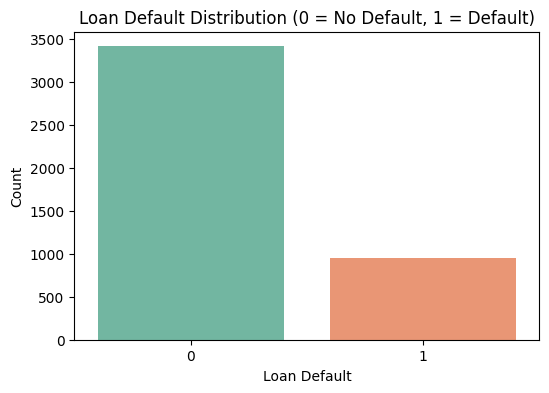


 CORRELATION HEATMAP (Numerical Features):


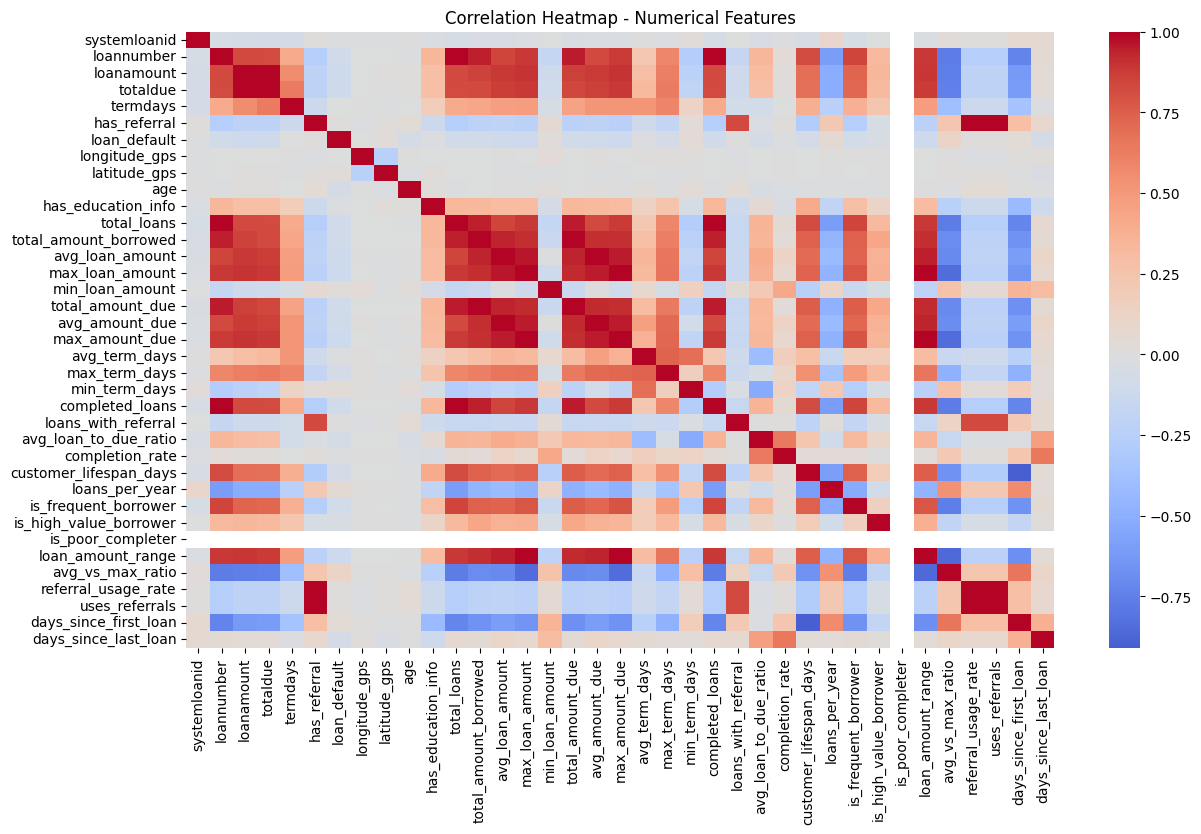


 DESCRIPTIVE STATISTICS (Selected Features):
                  count          mean           std      min       25%  \
loanamount       4368.0  17809.065934  10749.694571  10000.0  10000.00   
totaldue         4368.0  21257.377679  11943.510416  10000.0  13000.00   
termdays         4368.0     29.261676     11.512519     15.0     30.00   
age              4368.0     32.679945      5.318966     21.0     30.00   
total_loans      4368.0      4.162775      3.655952      0.0      1.00   
avg_loan_amount  4368.0  12882.906399   4849.816106      0.0  10000.00   
completion_rate  4368.0      0.997940      0.045350      0.0      1.00   
loans_per_year   4368.0    130.445723    162.172310      0.0     13.77   

                      50%       75%       max  
loanamount       10000.00  20000.00  60000.00  
totaldue         13000.00  24500.00  68100.00  
termdays            30.00     30.00     90.00  
age                 32.00     35.00     56.00  
total_loans          3.00      6.00     26.00  

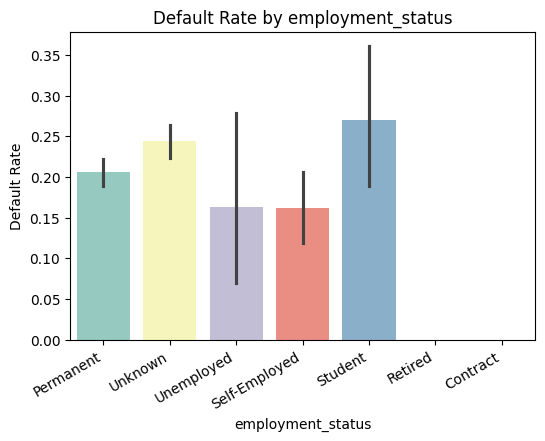

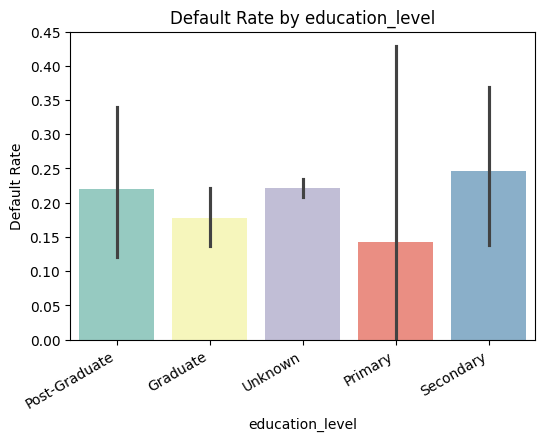

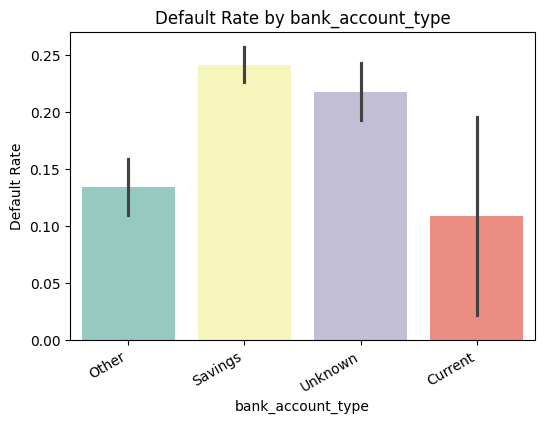

In [ ]:
#   Exploratory Data Analysis (EDA) - Overview

import matplotlib.pyplot as plt
import seaborn as sns



# 1. Dataset overview
print("\n DATASET OVERVIEW:")
print(ml_dataset.info())
print("\nQuick look at first 5 rows:")
display(ml_dataset.head())

# 2. Target variable distribution
print("\n TARGET VARIABLE DISTRIBUTION:")
target_counts = ml_dataset['loan_default'].value_counts().sort_index()
print(target_counts)

plt.figure(figsize=(6,4))
sns.countplot(data=ml_dataset, x='loan_default', palette='Set2')
plt.title("Loan Default Distribution (0 = No Default, 1 = Default)")
plt.xlabel("Loan Default")
plt.ylabel("Count")
plt.show()

# 3. Correlation heatmap (numerical features only)
print("\n CORRELATION HEATMAP (Numerical Features):")
plt.figure(figsize=(14,8))
sns.heatmap(
    ml_dataset.corr(numeric_only=True),
    cmap="coolwarm", center=0, annot=False
)
plt.title("Correlation Heatmap - Numerical Features")
plt.show()

# 4. Descriptive statistics for key numeric features
print("\n DESCRIPTIVE STATISTICS (Selected Features):")
num_features = [
    'loanamount', 'totaldue', 'termdays', 'age',
    'total_loans', 'avg_loan_amount', 'completion_rate',
    'loans_per_year'
]
print(ml_dataset[num_features].describe().T)

# 5. Default rate by categorical features
print("\n DEFAULT RATE BY CATEGORICAL FEATURES:")

cat_features = ['employment_status', 'education_level', 'bank_account_type']
for col in cat_features:

    plt.figure(figsize=(6,4))

    sns.barplot(
        data=ml_dataset, x=col, y='loan_default',
        estimator=lambda x: sum(x)/len(x), palette="Set3"
    )
    plt.title(f"Default Rate by {col}")
    plt.xticks(rotation=30, ha='right')
    plt.ylabel("Default Rate")
    plt.show()


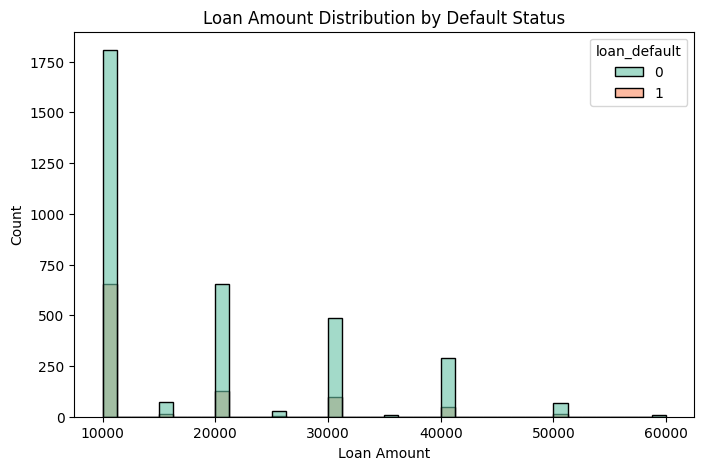

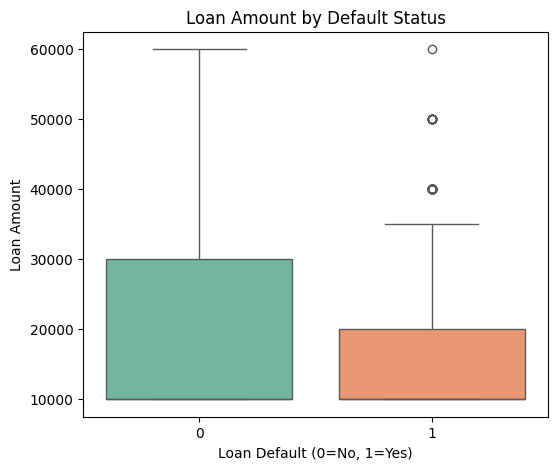

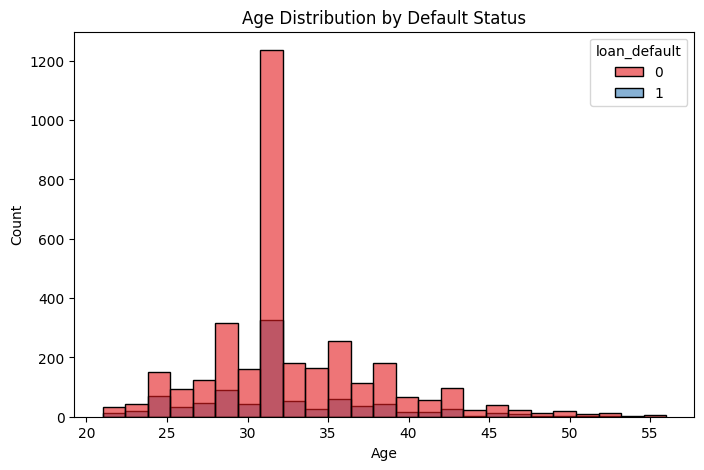

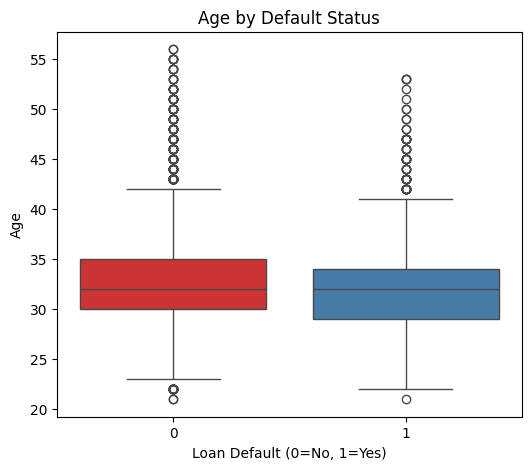

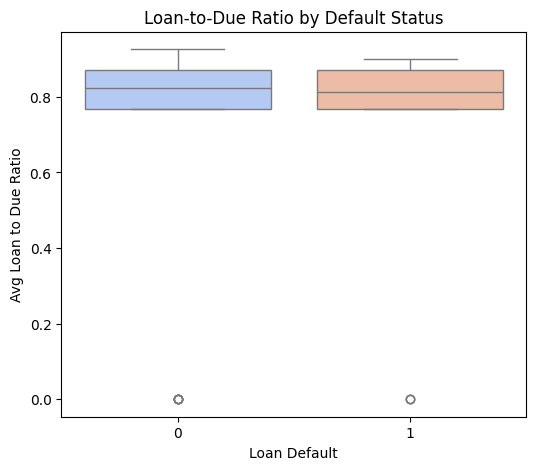

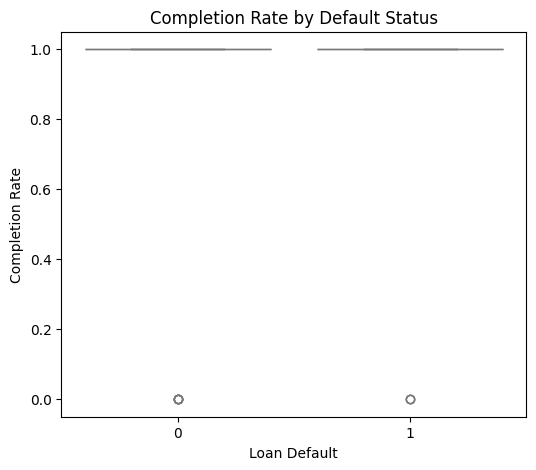

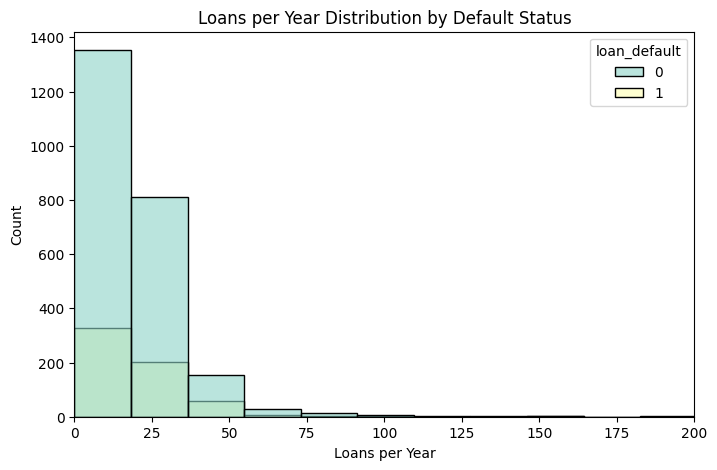

In [ ]:
#   EDA - Numerical Features Analysis

# 1. Distribution of Loan Amounts by Default
plt.figure(figsize=(8,5))
sns.histplot(data=ml_dataset, x='loanamount', hue='loan_default',
             bins=40, kde=False, palette='Set2', alpha=0.6)
plt.title("Loan Amount Distribution by Default Status")
plt.xlabel("Loan Amount")
plt.ylabel("Count")
plt.show()

# Boxplot for clearer comparison
plt.figure(figsize=(6,5))
sns.boxplot(data=ml_dataset, x='loan_default', y='loanamount', palette='Set2')
plt.title("Loan Amount by Default Status")
plt.xlabel("Loan Default (0=No, 1=Yes)")
plt.ylabel("Loan Amount")
plt.show()


# 2. Age distribution by Default
plt.figure(figsize=(8,5))
sns.histplot(data=ml_dataset, x='age', hue='loan_default',
             bins=25, kde=False, palette='Set1', alpha=0.6)
plt.title("Age Distribution by Default Status")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# Boxplot
plt.figure(figsize=(6,5))
sns.boxplot(data=ml_dataset, x='loan_default', y='age', palette='Set1')
plt.title("Age by Default Status")
plt.xlabel("Loan Default (0=No, 1=Yes)")
plt.ylabel("Age")
plt.show()


# 3. Loan-to-Due Ratio vs Default
plt.figure(figsize=(6,5))
sns.boxplot(data=ml_dataset, x='loan_default', y='avg_loan_to_due_ratio', palette='coolwarm')
plt.title("Loan-to-Due Ratio by Default Status")
plt.xlabel("Loan Default")
plt.ylabel("Avg Loan to Due Ratio")
plt.show()


# 4. Completion Rate vs Default
plt.figure(figsize=(6,5))
sns.boxplot(data=ml_dataset, x='loan_default', y='completion_rate', palette='coolwarm')
plt.title("Completion Rate by Default Status")
plt.xlabel("Loan Default")
plt.ylabel("Completion Rate")
plt.show()


# 5. Loans per Year vs Default
plt.figure(figsize=(8,5))
sns.histplot(data=ml_dataset, x='loans_per_year', hue='loan_default',
             bins=40, kde=False, palette='Set3', alpha=0.6)
plt.xlim(0, 200)   # limit extreme outliers for clarity
plt.title("Loans per Year Distribution by Default Status")
plt.xlabel("Loans per Year")
plt.ylabel("Count")
plt.show()


In [ ]:
print("Statistical Summary by Loan Default (0 = No, 1 = Yes)")
print("=" * 60)

num_cols_to_check = [
    'loanamount', 'age', 'avg_loan_to_due_ratio',
    'completion_rate', 'loans_per_year'
]

# Group means, medians, and counts for each target group
stats = ml_dataset.groupby('loan_default')[num_cols_to_check].agg(['mean','median','std','min','max','count'])
print(stats)

# Difference between defaulters vs non-defaulters
print("\n Mean Difference (Defaulters - Non-Defaulters):")
diff = stats.loc[1] - stats.loc[0]
print(diff)

CATEGORICAL FEATURE ANALYSIS

 EMPLOYMENT_STATUS - Default Rate Summary
                   num_customers  default_rate
employment_status                             
Student                      111      0.270270
Unknown                     1592      0.244347
Permanent                   2340      0.205556
Unemployed                    43      0.162791
Self-Employed                277      0.162455
Retired                        4      0.000000
Contract                       1      0.000000


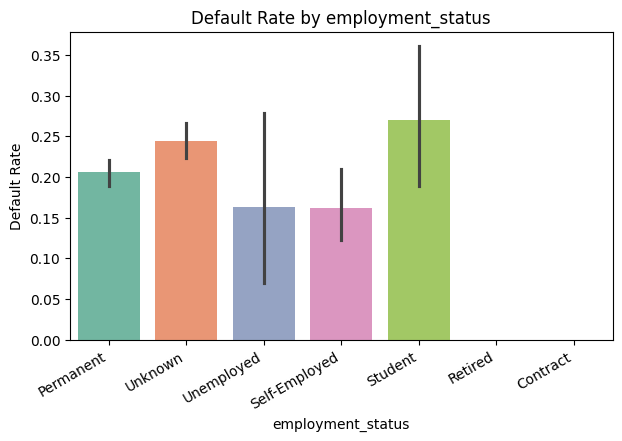


 EDUCATION_LEVEL - Default Rate Summary
                 num_customers  default_rate
education_level                             
Secondary                   65      0.246154
Unknown                   3925      0.220892
Post-Graduate               50      0.220000
Graduate                   321      0.177570
Primary                      7      0.142857


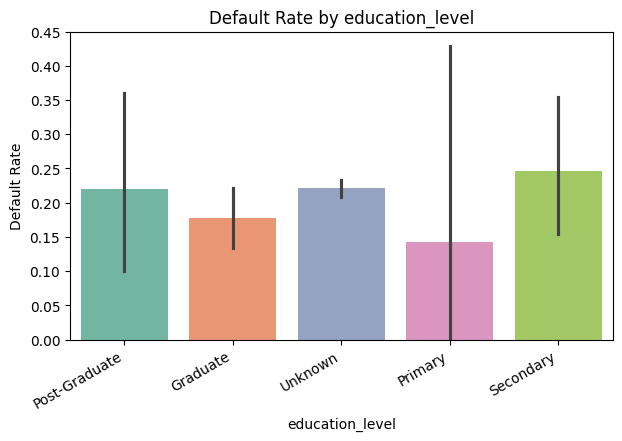


 BANK_ACCOUNT_TYPE - Default Rate Summary
                   num_customers  default_rate
bank_account_type                             
Savings                     2570      0.241245
Unknown                     1099      0.217470
Other                        653      0.134763
Current                       46      0.108696


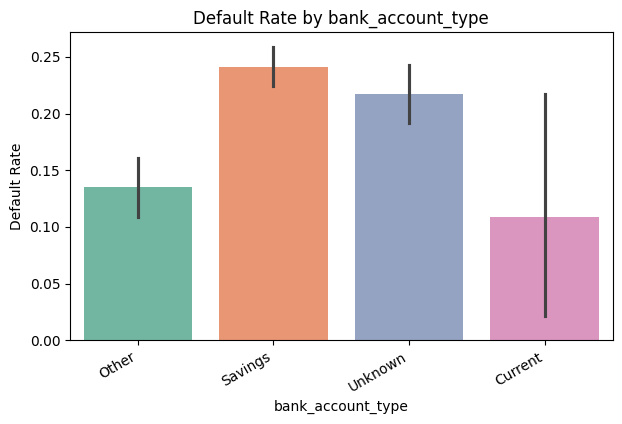


 BANK_NAME_CLIENTS - Default Rate Summary
                    num_customers  default_rate
bank_name_clients                              
Sterling Bank                  42      0.357143
Skye Bank                      75      0.280000
EcoBank                       116      0.258621
FCMB                           89      0.258427
Access Bank                   328      0.237805
Fidelity Bank                  74      0.229730
UBA                           267      0.228464
Zenith Bank                   224      0.227679
First Bank                    430      0.220930
Unknown                      1099      0.217470
GT Bank                      1207      0.216239
Keystone Bank                  14      0.214286
Unity Bank                      5      0.200000
Heritage Bank                  18      0.166667
Stanbic IBTC                  117      0.153846
Diamond Bank                  216      0.143519
Union Bank                     15      0.133333
Wema Bank                      19      0.1052

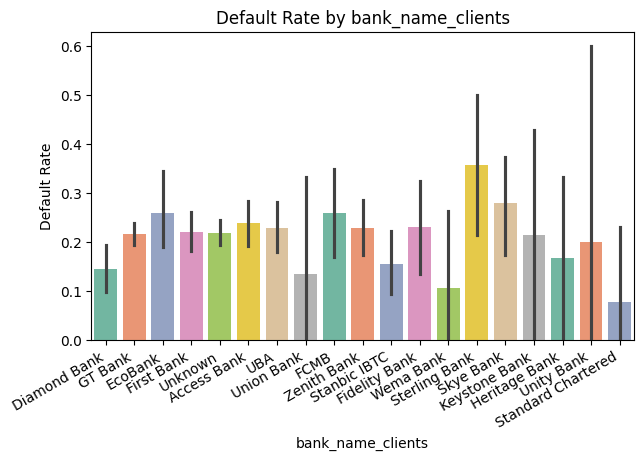


 HAS_REFERRAL - Default Rate Summary
              num_customers  default_rate
has_referral                             
True                    587      0.228279
False                  3781      0.216345


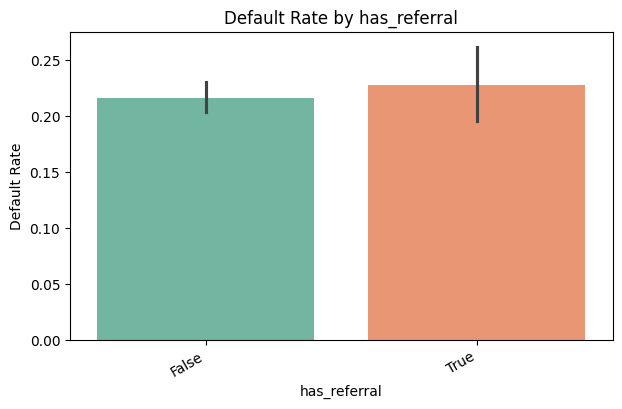


 USES_REFERRALS - Default Rate Summary
                num_customers  default_rate
uses_referrals                             
1.0                       587      0.228279
0.0                      3781      0.216345


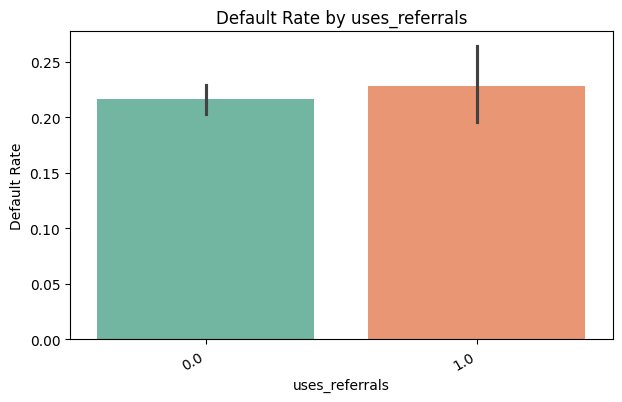

In [ ]:
print("CATEGORICAL FEATURE ANALYSIS")
print("=" * 50)

cat_features = [
    'employment_status',
    'education_level',
    'bank_account_type',
    'bank_name_clients',
    'has_referral',
    'uses_referrals'
]

for col in cat_features:
    print(f"\n {col.upper()} - Default Rate Summary")
    summary = ml_dataset.groupby(col)['loan_default'].agg(['count','mean'])
    summary = summary.rename(columns={'count': 'num_customers', 'mean': 'default_rate'})
    print(summary.sort_values('default_rate', ascending=False))

    # Plot default rates
    plt.figure(figsize=(7,4))
    sns.barplot(
        data=ml_dataset,
        x=col, y='loan_default',
        estimator=lambda x: sum(x)/len(x),
        palette="Set2"
    )
    plt.title(f"Default Rate by {col}")
    plt.ylabel("Default Rate")
    plt.xticks(rotation=30, ha='right')
    plt.show()

In [ ]:
print(" CATEGORICAL FEATURE DEFAULT RATES")
print("=" * 60)

cat_features = [
    'employment_status',
    'education_level',
    'bank_account_type',
    'bank_name_clients',
    'has_referral',
    'uses_referrals'
]

for col in cat_features:
    print(f"\n {col.upper()} - Default Rate Summary")
    summary = ml_dataset.groupby(col)['loan_default'].agg(
        num_customers='count',
        defaults='sum',
        default_rate='mean'
    ).sort_values('default_rate', ascending=False)
    print(summary)

 CATEGORICAL FEATURE DEFAULT RATES

 EMPLOYMENT_STATUS - Default Rate Summary
                   num_customers  defaults  default_rate
employment_status                                       
Student                      111        30      0.270270
Unknown                     1592       389      0.244347
Permanent                   2340       481      0.205556
Unemployed                    43         7      0.162791
Self-Employed                277        45      0.162455
Retired                        4         0      0.000000
Contract                       1         0      0.000000

 EDUCATION_LEVEL - Default Rate Summary
                 num_customers  defaults  default_rate
education_level                                       
Secondary                   65        16      0.246154
Unknown                   3925       867      0.220892
Post-Graduate               50        11      0.220000
Graduate                   321        57      0.177570
Primary                      7        

FEATURE IMPORTANCE PREVIEW (Using Mutual Information)
                  Feature  MI_Score
5       bank_account_type  0.019680
20         max_amount_due  0.016486
34       avg_vs_max_ratio  0.016186
13            total_loans  0.012505
22          max_term_days  0.011997
30   is_frequent_borrower  0.011232
15        avg_loan_amount  0.011090
1              loanamount  0.010544
14  total_amount_borrowed  0.010331
2                totaldue  0.009106
33      loan_amount_range  0.008550
36         uses_referrals  0.007604
27        completion_rate  0.007377
12        education_level  0.006965
35    referral_usage_rate  0.006910


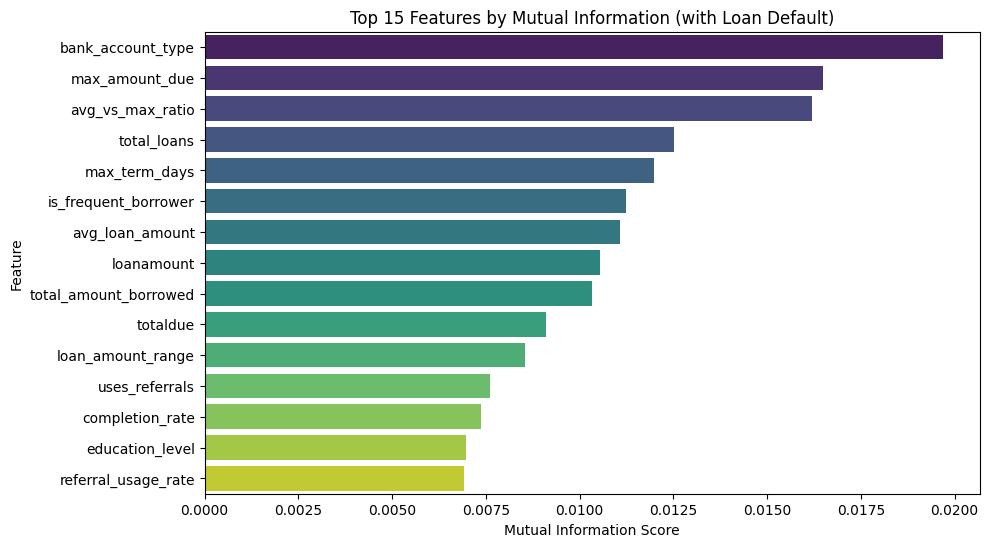

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

print("FEATURE IMPORTANCE PREVIEW (Using Mutual Information)")
print("=" * 70)

# Copy dataset to avoid touching original
X = ml_dataset.drop(columns=['loan_default', 'customerid', 'systemloanid', 'approveddate', 'creationdate'])
y = ml_dataset['loan_default']

# Encode categorical features
X_encoded = X.copy()
for col in X_encoded.select_dtypes(include=['object']).columns:
    X_encoded[col] = LabelEncoder().fit_transform(X_encoded[col])

# Mutual Information (captures non-linear dependencies)
mi_scores = mutual_info_classif(X_encoded, y, discrete_features='auto', random_state=42)

# Put in DataFrame
mi_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print(mi_df.head(15))   # show top 15 most important features

# Plot
plt.figure(figsize=(10,6))
sns.barplot(data=mi_df.head(15), x='MI_Score', y='Feature', palette='viridis')
plt.title("Top 15 Features by Mutual Information (with Loan Default)")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

print(" DATA PREPROCESSING FOR MODELING")
print("=" * 60)

# 1. Drop non-informative / leakage columns
X = ml_dataset.drop(columns=[
    'loan_default',
    'customerid',
    'systemloanid',
    'approveddate',
    'creationdate'
])
y = ml_dataset['loan_default']

# 2. Encode categorical variables
X_encoded = X.copy()

# Label encode object-type categorical columns
for col in X_encoded.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    print(f"Encoded: {col}")

# Convert boolean to int
for col in X_encoded.select_dtypes(include=['bool']).columns:
    X_encoded[col] = X_encoded[col].astype(int)
    print(f"Converted bool -> int: {col}")

print("\nCategorical encoding complete.")

# 3. Scale numerical features
scaler = StandardScaler()
X_scaled = X_encoded.copy()
num_cols = X_scaled.select_dtypes(include=['float64','int64']).columns

X_scaled[num_cols] = scaler.fit_transform(X_scaled[num_cols])
print(" Numerical features scaled.")

# 4. Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

print("\n Dataset split complete:")
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")
print(f"Target distribution in train: {y_train.value_counts(normalize=True).to_dict()}")
print(f"Target distribution in test: {y_test.value_counts(normalize=True).to_dict()}")

 DATA PREPROCESSING FOR MODELING
Encoded: bank_account_type
Encoded: bank_name_clients
Encoded: employment_status
Encoded: education_level
Converted bool -> int: has_referral
Converted bool -> int: has_education_info

Categorical encoding complete.
 Numerical features scaled.

 Dataset split complete:
Train set: (3494, 39), Test set: (874, 39)
Target distribution in train: {0: 0.7819118488838008, 1: 0.2180881511161992}
Target distribution in test: {0: 0.782608695652174, 1: 0.21739130434782608}


 BASELINE MODEL COMPARISON

 Baseline Model Performance:
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
2              XGBoost  0.768879   0.416667  0.157895  0.229008  0.629017
0  Logistic Regression  0.781465   0.333333  0.005263  0.010363  0.615609
1        Random Forest  0.772311   0.404255  0.100000  0.160338  0.603166
3                  SVM  0.782609   0.000000  0.000000  0.000000  0.562361


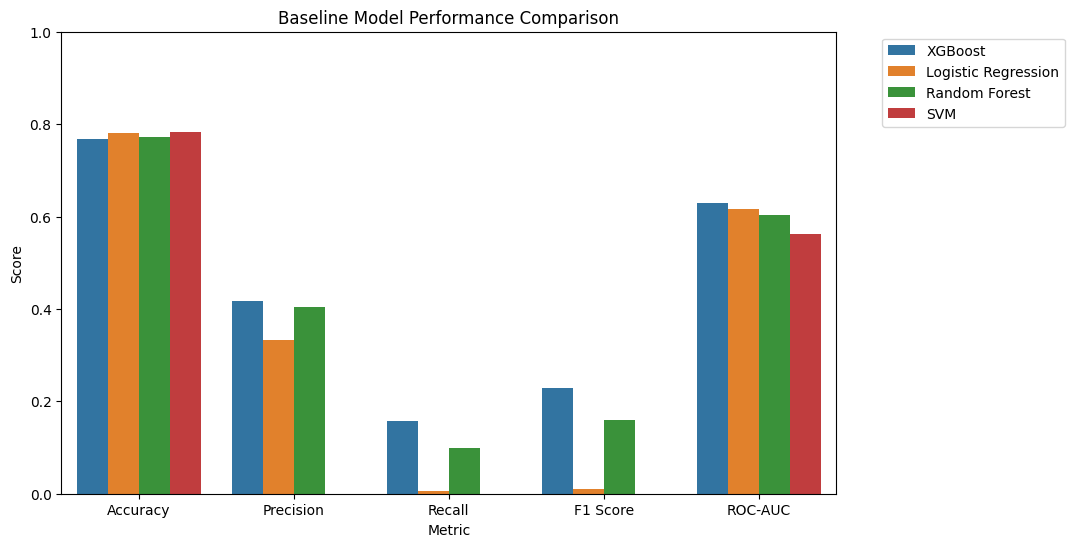

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

print(" BASELINE MODEL COMPARISON")
print("=" * 60)

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

results = []

# Train & evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

# Results table
results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n Baseline Model Performance:")
print(results_df)

# Plot comparison
plt.figure(figsize=(10,6))
sns.barplot(data=results_df.melt(id_vars="Model", var_name="Metric", value_name="Score"),
            x="Metric", y="Score", hue="Model")
plt.title("Baseline Model Performance Comparison")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print(" HANDLING CLASS IMBALANCE (Class Weights + SMOTE)")
print("=" * 70)

# Apply SMOTE only on training set
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Original training distribution: {y_train.value_counts().to_dict()}")
print(f"Resampled training distribution: {y_train_res.value_counts().to_dict()}")

# Define models with class_weight balanced where supported
models_balanced = {
    "Logistic Regression (Weighted)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest (Weighted)": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
    "XGBoost (Weighted)": XGBClassifier(scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),
                                        use_label_encoder=False, eval_metric='logloss', random_state=42)
}

results_balanced = []

# Train & evaluate
for name, model in models_balanced.items():
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results_balanced.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

# Results table
results_balanced_df = pd.DataFrame(results_balanced).sort_values(by="ROC-AUC", ascending=False)
print("\n Performance After Imbalance Handling:")
print(results_balanced_df)

 HANDLING CLASS IMBALANCE (Class Weights + SMOTE)
Original training distribution: {0: 2732, 1: 762}
Resampled training distribution: {0: 2732, 1: 2732}

 Performance After Imbalance Handling:
                            Model  Accuracy  Precision    Recall  F1 Score  \
2              XGBoost (Weighted)  0.651030   0.306397  0.478947  0.373717   
0  Logistic Regression (Weighted)  0.561785   0.270784  0.600000  0.373159   
1        Random Forest (Weighted)  0.713959   0.300000  0.236842  0.264706   

    ROC-AUC  
2  0.617544  
0  0.607329  
1  0.598126  


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

print(" HYPERPARAMETER TUNING")
print("=" * 70)

# -------------------------------
# Logistic Regression Tuning
# -------------------------------
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)

param_dist_lr = {
    "C": uniform(0.01, 10),   # Regularization strength
    "solver": ["liblinear", "saga", "lbfgs"]
}

lr_search = RandomizedSearchCV(
    log_reg, param_distributions=param_dist_lr,
    n_iter=20, scoring="roc_auc", cv=5, random_state=42, n_jobs=-1
)

lr_search.fit(X_train_res, y_train_res)

print("\nBest Logistic Regression Params:", lr_search.best_params_)
print("Best ROC-AUC (CV):", lr_search.best_score_)

# Evaluate on test set
y_pred_lr = lr_search.best_estimator_.predict(X_test)
y_proba_lr = lr_search.best_estimator_.predict_proba(X_test)[:,1]

lr_results = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr),
    "Recall": recall_score(y_test, y_pred_lr),
    "F1 Score": f1_score(y_test, y_pred_lr),
    "ROC-AUC": roc_auc_score(y_test, y_proba_lr)
}
print("\n Logistic Regression (Tuned) Test Results:", lr_results)


# -------------------------------
# XGBoost Tuning
# -------------------------------
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

param_dist_xgb = {
    "n_estimators": randint(100, 500),
    "max_depth": randint(3, 10),
    "learning_rate": uniform(0.01, 0.3),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "scale_pos_weight": [y_train.value_counts()[0] / y_train.value_counts()[1]]
}

xgb_search = RandomizedSearchCV(
    xgb, param_distributions=param_dist_xgb,
    n_iter=20, scoring="roc_auc", cv=5, random_state=42, n_jobs=-1
)

xgb_search.fit(X_train_res, y_train_res)

print("\nBest XGBoost Params:", xgb_search.best_params_)
print("Best ROC-AUC (CV):", xgb_search.best_score_)

# Evaluate on test set
y_pred_xgb = xgb_search.best_estimator_.predict(X_test)
y_proba_xgb = xgb_search.best_estimator_.predict_proba(X_test)[:,1]

xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1 Score": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_proba_xgb)
}
print("\n XGBoost (Tuned) Test Results:", xgb_results)

 HYPERPARAMETER TUNING

Best Logistic Regression Params: {'C': np.float64(9.842308858067883), 'solver': 'liblinear'}
Best ROC-AUC (CV): 0.6268300515292098

 Logistic Regression (Tuned) Test Results: {'Accuracy': 0.5617848970251716, 'Precision': 0.27294117647058824, 'Recall': 0.6105263157894737, 'F1 Score': 0.3772357723577236, 'ROC-AUC': np.float64(0.6061595875654048)}

Best XGBoost Params: {'colsample_bytree': np.float64(0.935552788417904), 'learning_rate': np.float64(0.06990213464750791), 'max_depth': 9, 'n_estimators': 343, 'scale_pos_weight': np.float64(3.5853018372703414), 'subsample': np.float64(0.8777243706586126)}
Best ROC-AUC (CV): 0.9188035285725986

 XGBoost (Tuned) Test Results: {'Accuracy': 0.6922196796338673, 'Precision': 0.329004329004329, 'Recall': 0.4, 'F1 Score': 0.36104513064133015, 'ROC-AUC': np.float64(0.616539704524469)}


In [ ]:
# Collect all results
comparison = pd.DataFrame([
    # Baseline
    {"Stage": "Baseline", "Model": "Logistic Regression", "Accuracy": 0.781, "Precision": 0.333, "Recall": 0.005, "F1": 0.010, "ROC-AUC": 0.616},
    {"Stage": "Baseline", "Model": "Random Forest", "Accuracy": 0.772, "Precision": 0.404, "Recall": 0.100, "F1": 0.160, "ROC-AUC": 0.603},
    {"Stage": "Baseline", "Model": "XGBoost", "Accuracy": 0.769, "Precision": 0.417, "Recall": 0.158, "F1": 0.229, "ROC-AUC": 0.629},
    {"Stage": "Baseline", "Model": "SVM", "Accuracy": 0.783, "Precision": 0.000, "Recall": 0.000, "F1": 0.000, "ROC-AUC": 0.562},

    # Weighted / SMOTE
    {"Stage": "Weighted/SMOTE", "Model": "Logistic Regression", "Accuracy": 0.562, "Precision": 0.271, "Recall": 0.600, "F1": 0.373, "ROC-AUC": 0.607},
    {"Stage": "Weighted/SMOTE", "Model": "Random Forest", "Accuracy": 0.714, "Precision": 0.300, "Recall": 0.237, "F1": 0.265, "ROC-AUC": 0.598},
    {"Stage": "Weighted/SMOTE", "Model": "XGBoost", "Accuracy": 0.651, "Precision": 0.306, "Recall": 0.479, "F1": 0.374, "ROC-AUC": 0.618},

    # Tuned
    {"Stage": "Tuned", "Model": "Logistic Regression", "Accuracy": 0.562, "Precision": 0.273, "Recall": 0.611, "F1": 0.377, "ROC-AUC": 0.606},
    {"Stage": "Tuned", "Model": "XGBoost", "Accuracy": 0.692, "Precision": 0.329, "Recall": 0.400, "F1": 0.361, "ROC-AUC": 0.617},
])

# Round results
comparison = comparison.round(3)

print(" FINAL MODEL COMPARISON (Baseline → Weighted/SMOTE → Tuned)")
print("=" * 80)
print(comparison)

 FINAL MODEL COMPARISON (Baseline → Weighted/SMOTE → Tuned)
            Stage                Model  Accuracy  Precision  Recall     F1  \
0        Baseline  Logistic Regression     0.781      0.333   0.005  0.010   
1        Baseline        Random Forest     0.772      0.404   0.100  0.160   
2        Baseline              XGBoost     0.769      0.417   0.158  0.229   
3        Baseline                  SVM     0.783      0.000   0.000  0.000   
4  Weighted/SMOTE  Logistic Regression     0.562      0.271   0.600  0.373   
5  Weighted/SMOTE        Random Forest     0.714      0.300   0.237  0.265   
6  Weighted/SMOTE              XGBoost     0.651      0.306   0.479  0.374   
7           Tuned  Logistic Regression     0.562      0.273   0.611  0.377   
8           Tuned              XGBoost     0.692      0.329   0.400  0.361   

   ROC-AUC  
0    0.616  
1    0.603  
2    0.629  
3    0.562  
4    0.607  
5    0.598  
6    0.618  
7    0.606  
8    0.617  


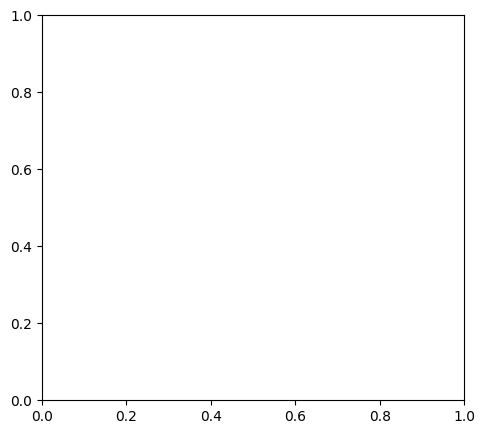

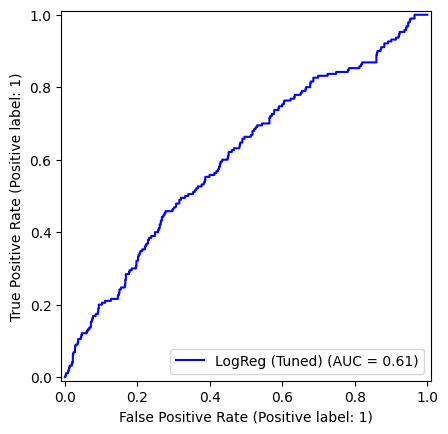

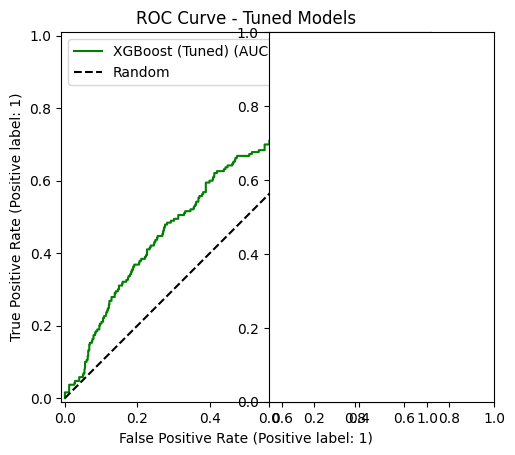

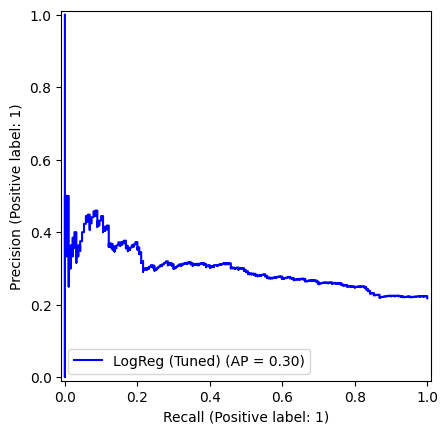

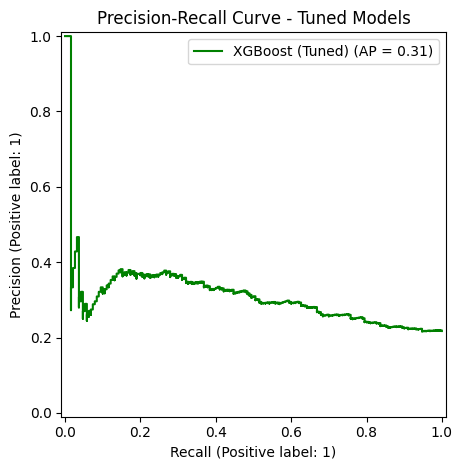

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Get tuned models
best_lr = lr_search.best_estimator_
best_xgb = xgb_search.best_estimator_

# Predict probabilities
y_proba_lr = best_lr.predict_proba(X_test)[:,1]
y_proba_xgb = best_xgb.predict_proba(X_test)[:,1]

# --- ROC Curves ---
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="LogReg (Tuned)", color="blue")
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost (Tuned)", color="green")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.title("ROC Curve - Tuned Models")
plt.legend()

# --- Precision-Recall Curves ---
plt.subplot(1, 2, 2)
PrecisionRecallDisplay.from_predictions(y_test, y_proba_lr, name="LogReg (Tuned)", color="blue")
PrecisionRecallDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost (Tuned)", color="green")
plt.title("Precision-Recall Curve - Tuned Models")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE

print(" Building Final Pipeline for Deployment")

# Separate feature types
categorical_features = ["bank_account_type", "bank_name_clients", "employment_status", "education_level"]
numeric_features = [col for col in X.columns if col not in categorical_features]

# Preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

# Choose best model (XGBoost or Logistic Regression)
final_model = xgb_search.best_estimator_   # <-- change to lr_search.best_estimator_ if you prefer Logistic Regression

# Full pipeline with SMOTE + preprocessing + model
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", final_model)
])

# Fit pipeline
pipeline.fit(X_train, y_train)

# Evaluate on test set
y_pred_final = pipeline.predict(X_test)
y_proba_final = pipeline.predict_proba(X_test)[:,1]

final_results = {
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall": recall_score(y_test, y_pred_final),
    "F1 Score": f1_score(y_test, y_pred_final),
    "ROC-AUC": roc_auc_score(y_test, y_proba_final)
}

print("\n Final Pipeline Test Results:", final_results)

 Building Final Pipeline for Deployment

 Final Pipeline Test Results: {'Accuracy': 0.7105263157894737, 'Precision': 0.3574660633484163, 'Recall': 0.41578947368421054, 'F1 Score': 0.3844282238442822, 'ROC-AUC': np.float64(0.6389389042782395)}


In [ ]:
import joblib

# Save the final pipeline
joblib.dump(pipeline, "loan_default_final_model.pkl")
print(" Final pipeline saved as loan_default_final_model.pkl")

# Example: Load the model back
loaded_model = joblib.load("loan_default_final_model.pkl")

# Test on a small sample
sample_pred = loaded_model.predict(X_test.iloc[:5])
print("\n Sample Predictions for first 5 test cases:", sample_pred)


 Final pipeline saved as loan_default_final_model.pkl

 Sample Predictions for first 5 test cases: [0 1 1 0 0]


In [ ]:
# Ensure new_customer has all training columns
new_customer = pd.DataFrame(columns=X.columns)  # create empty with same cols
new_customer.loc[0] = 0  # fill with zeros as default

# Now update with real values for one applicant
new_customer.loc[0, :] = {
    "loanamount": 20000,
    "totaldue": 24000,
    "termdays": 30,
    "has_referral": 0,
    "bank_account_type": "Savings",
    "longitude_gps": 7.45,
    "latitude_gps": 9.05,
    "bank_name_clients": "First Bank",
    "employment_status": "Permanent",
    "age": 32,
    "has_education_info": 1,
    "education_level": "Graduate",
    "total_loans": 5,
    "total_amount_borrowed": 85000,
    "avg_loan_amount": 17000,
    "max_loan_amount": 30000,
    "min_loan_amount": 10000,
    "total_amount_due": 102000,
    "avg_amount_due": 20400,
    "max_amount_due": 30000,
    "avg_term_days": 25,
    "max_term_days": 30,
    "min_term_days": 15,
    "completed_loans": 4,
    "loans_with_referral": 1,
    "avg_loan_to_due_ratio": 0.85,
    "completion_rate": 0.95,
    "customer_lifespan_days": 500,
    "loans_per_year": 15,
    "is_frequent_borrower": 1,
    "is_high_value_borrower": 0,
    "is_poor_completer": 0,
    "loan_amount_range": 20000,
    "avg_vs_max_ratio": 0.566,
    "referral_usage_rate": 0.2,
    "uses_referrals": 1,
    "days_since_first_loan": 600,
    "days_since_last_loan": 60,
    # fill the remaining technical/system columns with neutral values
    "customerid": "new_001",
    "systemloanid": 999999,
    "loannumber": 1,
    "approveddate": pd.Timestamp("2023-01-01"),
    "creationdate": pd.Timestamp("2023-01-01"),
}

# Predict default probability
default_prob = pipeline.predict_proba(new_customer)[:,1][0]
default_pred = pipeline.predict(new_customer)[0]

print("Prediction for New Customer:")
print(f"Probability of Default: {default_prob:.2f}")
print("Predicted Class:", "Default" if default_pred == 1 else "No Default")

Prediction for New Customer:
Probability of Default: 0.01
Predicted Class: No Default
